<font face="Times New Roman" size=5>
<div dir=rtl align="center">
<font face="Times New Roman" size=5>
In The Name of God
</font>
<br>
<img src="https://logoyar.com/content/wp-content/uploads/2021/04/sharif-university-logo.png" alt="University Logo" width="150" height="150">
<br>
<font face="Times New Roman" size=4 align=center>
Sharif University of Technology - Department of Electrical Engineering
</font>
<br>
<font color="#008080" size=6>
Deep Generative Models
</font>
<hr/>
<font color="#800080" size=5>
Assignment 2 : Deep Autoregressive Models
<br>
</font>
<font size=5>
Instructor: Dr. S. Amini
<br>
</font>
<font size=4>
Fall 2025
<br>
</font>
<font face="Times New Roman" size=4>
</font>
<hr>
<font color='red'  size=4>
<br>
</font>
<font face="Times New Roman" size=4 align=center>
Feel free to ask your questions in Telegram : @ZahraSorkhei, @Ali99os
</font>
<br>
<hr>
</div></font>

**You should only change the blank sections, marked with TODO**

Pay attention to docstrings, as they may drastically help with your implementation.

You are advised to read all related papers and material, to help you better understand the design of each model.

# Question 1: Probabilistic Graph Forecasting with Autoregressive Decoders

This note gives a concise introduction to a temporal latent-variable model for **graph sequences** $\{G_t\}_{t=1}^T$ with $G_t=(X_t,A_t)$. It states the model, the training objective (ELBO) in a time-factorized form, the concrete likelihoods used for node features and edges, the effect of a deterministic decoder, and how to generate future graphs.



## Problem setup

We observe a sequence of graph snapshots

$$
G_t = (X_t, A_t), \quad t=1,\dots,T,
$$

where $X_t \in \mathbb{R}^{n \times d}$ stacks node feature vectors $x_t^v$ and $A_t \in \{0,1\}^{n \times n}$ is an undirected adjacency matrix (no self-loops). To capture temporal structure we introduce a latent trajectory

$$
Z_{1:T} = (Z_1, \dots, Z_T), \quad Z_t \in \mathbb{R}^m,
$$

where $Z_t$ is a global latent representation of the whole graph at time $t$.


## Generative (autoregressive latent) model

An autoregressive factorization is used:

$$
p_\theta(X_{1:T}, A_{1:T}, Z_{1:T})
= p(Z_1) \prod_{t=1}^{T-1} p_\theta(Z_{t+1}\mid Z_t)\; p_\theta(X_{t+1}, A_{t+1}\mid Z_t)
$$

Intuition: the latent $Z_t$ summarizes the state at $t$; a transition model $p_\theta(Z_{t+1}\mid Z_t)$ evolves it; conditioned on the current latent we predict the *next* snapshot $(X_{t+1}, A_{t+1})$.

We approximate the true posterior with an amortized encoder (e.g. a GNN+RNN):

$$
q_\phi(Z_t \mid X_{1:t}, A_{1:t}) \quad \text{(often factorized across $t$ for amortization).}
$$


## Variational lower bound (ELBO) — time decomposition

Using the variational approximation

$$
q_\phi(Z_{1:T}\mid X_{1:T},A_{1:T}) = \prod_{t=1}^T q_\phi(Z_t \mid X_{1:t},A_{1:t}),
$$

the marginal log-likelihood admits the ELBO:

$$
\log p_\theta(X_{1:T}, A_{1:T}) \ge
\mathbb{E}_{q_\phi} \Big[ \sum_{t=1}^{T-1} \log p_\theta(X_{t+1}, A_{t+1} \mid Z_t) \Big]
- \mathrm{KL}\big(q_\phi(Z_1 \mid X_1, A_1) \,\|\, p(Z_1)\big)
- \sum_{t=1}^{T-1} \mathbb{E}_{q_\phi} \Big[ \mathrm{KL}\big(q_\phi(Z_{t+1}\mid X_{1:t+1}, A_{1:t+1}) \,\|\, p_\theta(Z_{t+1}\mid Z_t)\big) \Big].
$$

Thus the objective is a sum over time: per-step reconstruction terms plus per-step KL penalties that align the encoder's posterior with the learned transition prior.



## Explicit reconstruction likelihoods

If the decoder factorizes into Gaussian node-features and Bernoulli edges:

- **Node features (per node $v$)**

$$
p_\theta(x_{t+1}^v \mid Z_t) = \mathcal{N}(x_{t+1}^v \mid \mu_\theta^v(Z_t), \Sigma_\theta^v(Z_t)),
$$

hence the feature log-likelihood (for all nodes) is

$$
\log p_\theta(X_{t+1} \mid Z_t)
= -\frac{1}{2} \sum_{v=1}^n \Big[ (x_{t+1}^v - \mu_\theta^v)^\top (\Sigma_\theta^v)^{-1} (x_{t+1}^v - \mu_\theta^v) + \log \det(2 \pi \Sigma_\theta^v) \Big].
$$

(In practice $\Sigma^v$ is taken diagonal or shared for numerical stability.)

- **Edges (for unordered pairs $u<v$)**

$$
p_\theta(A_{t+1} \mid Z_t) = \prod_{u<v} \mathrm{Bernoulli}\big(A_{t+1}^{uv} \mid \pi_\theta^{uv}(Z_t)\big),
$$

so

$$
\log p_\theta(A_{t+1} \mid Z_t) = \sum_{u<v} \Big[ A_{uv} \log \pi_{uv} + (1-A_{uv}) \log (1-\pi_{uv}) \Big].
$$

Combine them:

$$
\log p_\theta(X_{t+1}, A_{t+1} \mid Z_t) = \log p_\theta(X_{t+1} \mid Z_t) + \log p_\theta(A_{t+1} \mid Z_t).
$$


## Deterministic decoder

If the decoder is deterministic (e.g. $X_{t+1}=f_\theta(Z_t)$, $A_{t+1}=g_\theta(Z_t)$ or equivalently Gaussian with vanishing variance), then:

- The likelihood becomes a Dirac (or degenerate Gaussian); log-likelihood is $-\infty$ off the model manifold — numerically unstable.
- Deterministic decoders cannot model multimodality: a single $Z_t$ maps to a single snapshot, so they fail when the conditional distribution is multi-valued.
- Training tends to overfit (model memorizes) or produce poor uncertainty calibration. Probabilistic decoders (non-zero variance, Bernoulli edges) are preferred for stable likelihood-based training and to capture uncertainty/diversity.


## Generating future graphs

Given observed history $X_{1:T}, A_{1:T}$:

1. Infer the posterior at final time: $q_\phi(Z_T \mid X_{1:T}, A_{1:T})$ and sample $z_T \sim q_\phi$ (or use the posterior mean).
2. For $h=1$ to $H$:
   - Sample latent: $z_{T+h} \sim p_\theta(Z_{T+h} \mid z_{T+h-1})$.
   - Sample (or take mean of) snapshot: $(\tilde X_{T+h}, \tilde A_{T+h}) \sim p_\theta(\cdot \mid z_{T+h-1})$ (or use the decoder mean).





In [1]:
import math, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import networkx as nx
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

## 1) Synthetic dynamic graph dataset
**Goal:**  
Create dynamic graphs using SBM with Gaussian node features.

**Hints:**  
- `generate_sbm`: adjacency with `p_in` (intra) and `p_out` (inter) edges.  
- `generate_features`: node features from `N(μ_k, Σ_k)` per community.  
- `generate_sequence`: simulate T timesteps with drift and edge flips.  
- `_getitem_` / `_len_`: return sequences.  
- `collate_fn`: batch multiple sequences.

**Output:**  
- `X_seq`: `[T, n_nodes, feat_dim]`  
- `A_seq`: `[T, n_nodes, n_nodes]`

In [2]:
class SyntheticGraphDataset(Dataset):
    """
    Generate synthetic evolving graphs.
    - Each sequence has T snapshots.
    - Node features: random walk.
    - Edges: flip with small probability.
    """
    def __init__(self, n_nodes=30, feat_dim=4, T=40, n_seq=200, p_flip=0.03,
                 n_communities = 3, p_in = 0.4, p_out = 0.05):
        super().__init__()
        self.n_nodes = n_nodes
        self.feat_dim = feat_dim
        self.T = T
        self.n_seq = n_seq
        self.p_flip = p_flip
        self.n_communities = n_communities
        self.p_in = p_in
        self.p_out = p_out
        self.communities = np.random.randint(0, n_communities, self.n_nodes)

        self.mu_list = [np.random.rand(self.feat_dim) * 5 for _ in range(n_communities)]
        self.sigma_list = [np.diag(np.random.rand(self.feat_dim) * 0.5 + 0.1) for _ in range(n_communities)]

        self.feature_noise_std = 0.1

        self.data = [self.generate_sequence() for _ in range(self.n_seq)]

    def _generate_sbm_adjacency(self):
        C = np.equal.outer(self.communities, self.communities)
        
        P = C * self.p_in + (~C) * self.p_out
        R = np.random.rand(self.n_nodes, self.n_nodes)
        A = (R < P).astype(int)
        
        A_upper = np.triu(A, k=1)
        A = A_upper + A_upper.T
        np.fill_diagonal(A, 0)
        
        return A

    def _generate_initial_features(self):
        unique_communities = np.unique(self.communities)
        features = np.empty((self.n_nodes, self.feat_dim))

        for comm_id in unique_communities:
            node_indices = np.where(self.communities == comm_id)[0]
            num_nodes = len(node_indices)

            if num_nodes > 0:
                mu = self.mu_list[comm_id]
                sigma = self.sigma_list[comm_id]
                
                community_features = np.random.multivariate_normal(mean=mu, cov=sigma, size=num_nodes)
                
                features[node_indices] = community_features

        return features


    def generate_sequence(self):
        X_seq = []
        A_seq = []

        current_A = self._generate_sbm_adjacency()
        current_X = self._generate_initial_features()
        
        X_seq.append(current_X)
        A_seq.append(current_A)

        for _ in range(1, self.T):
            R = np.random.rand(self.n_nodes, self.n_nodes)
            R = (R + R.T) / 2
            current_A = np.where(R < self.p_flip, 1 - current_A, current_A)
            np.fill_diagonal(current_A, 0)
            A_seq.append(current_A.copy())

            next_X = current_X + np.random.normal(0, self.feature_noise_std, size=(self.n_nodes, self.feat_dim))
            current_X = next_X
            X_seq.append(current_X.copy())

        return torch.tensor(np.array(X_seq), dtype=torch.float32), torch.tensor(np.array(A_seq), dtype=torch.float32)


    def __len__(self):
        return self.n_seq


    def __getitem__(self, idx):
        return self.data[idx]



def collate_fn(batch):
    X_seq_batch = torch.stack([item[0] for item in batch])
    A_seq_batch = torch.stack([item[1] for item in batch])

    return X_seq_batch, A_seq_batch


## 2) Encoder, Prior, Decoder

### SimpleGraphEncoder
Aggregates node features and degree statistics.  
Computes graph-level latent embeddings `mu` and `logvar` for VAE.  
No external graph libraries required; uses only PyTorch.

### TransitionPrior
Models the latent temporal evolution `p(Z_{t+1} | Z_t)` as a Gaussian.  
Produces mean and variance for autoregressive sampling in VAE.

### Decoder
Reconstructs node features and adjacency matrices from latent `Z_t`.  
Uses node embeddings combined with latent vectors for feature decoding.  
Produces edge logits for Bernoulli reconstruction of adjacency.  
Supports probabilistic reconstruction via Gaussian features + Bernoulli edges.

In [3]:
class SimpleGraphEncoder(nn.Module):
    """
    Simple encoder that aggregates node features and graph degree stats.
    No torch_geometric needed.
    """
    def __init__(self, n_nodes, feat_dim, z_dim):
        super().__init__()
        self.n_nodes = n_nodes
        self.feat_dim = feat_dim
        self.z_dim = z_dim

        self.fc1 = nn.Linear(feat_dim + 1, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc_mu = nn.Linear(64, z_dim)
        self.fc_logvar = nn.Linear(64, z_dim)

    def forward(self, x, a):
        mean_features = x.mean(dim=1)

        degrees = torch.sum(a, dim=-1)
        mean_degree = degrees.mean(dim=1, keepdim=True)

        h = torch.cat([mean_features, mean_degree], dim=-1)

        h = F.relu(self.fc1(h))
        h = F.relu(self.fc2(h))

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar


class TransitionPrior(nn.Module):
    """ p(Z_{t+1}|Z_t) Gaussian """
    def __init__(self, z_dim):
        super().__init__()
        self.z_dim = z_dim

        self.fc1 = nn.Linear(z_dim, 64)
        self.fc_mu = nn.Linear(64, z_dim)
        self.fc_logvar = nn.Linear(64, z_dim)

    def forward(self, z_t):
        # z_t: (batch_size, z_dim)
        h = F.relu(self.fc1(z_t))
        mu_p = self.fc_mu(h)
        logvar_p = self.fc_logvar(h)
        return mu_p, logvar_p


class Decoder(nn.Module):
    """ Decode node features and edges from Z_t """
    def __init__(self, n_nodes, feat_dim, z_dim):
        super().__init__()
        self.n_nodes = n_nodes
        self.feat_dim = feat_dim
        self.z_dim = z_dim
        self.num_edge_pairs = n_nodes * (n_nodes - 1) // 2

        self.fc_x_1 = nn.Linear(z_dim, 128)
        self.fc_x_mu = nn.Linear(128, n_nodes * feat_dim)
        self.fc_x_logvar = nn.Linear(128, n_nodes * feat_dim)

        self.fc_a_1 = nn.Linear(z_dim, 128)
        self.fc_a_logits = nn.Linear(128, self.num_edge_pairs)

    def forward(self, z_t):
        h_x = F.relu(self.fc_x_1(z_t))
        mu_x = self.fc_x_mu(h_x).view(-1, self.n_nodes, self.feat_dim)
        logvar_x = self.fc_x_logvar(h_x).view(-1, self.n_nodes, self.feat_dim)
        logvar_x = F.softplus(logvar_x)

        h_a = F.relu(self.fc_a_1(z_t))
        logits_a = self.fc_a_logits(h_a)

        return mu_x, logvar_x, logits_a

`reparameterize`: samples latent variable using the reparameterization trick.  
`kl_gauss`: closed-form KL divergence between two Gaussians.  
`nll_gaussian`: negative log-likelihood for node features.  
`nll_bernoulli`: negative log-likelihood (binary cross-entropy) for edges.

In [4]:
def reparameterize(mu, logvar):
    std = torch.exp(0.5 * logvar)
    eps = torch.randn_like(std)
    return mu + eps * std


def kl_gauss(mu_q, logvar_q, mu_p, logvar_p):
    """ closed-form KL(q||p) """
    kl_div = 0.5 * (logvar_p - logvar_q + 
                    (torch.exp(logvar_q) + (mu_q - mu_p).pow(2)) / torch.exp(logvar_p) - 1)
    return torch.sum(kl_div, dim=-1).mean()


def nll_gaussian(x, mu, logvar):
    nll = 0.5 * (logvar + (x - mu).pow(2) / torch.exp(logvar))
    return torch.sum(nll, dim=[1, 2]).mean()


def nll_bernoulli(logits, target):
    return F.binary_cross_entropy_with_logits(logits, target, reduction='sum').mean()


## 4) TemporalGraphVAE
Define the Temporal Graph VAE model.  
- Encode node features & adjacency into latent `z`.  
- Model transitions `p(z_{t+1}|z_t)`.  
- Decode `z` to reconstruct node features and edges.  
- Compute ELBO (reconstruction + KL) for training.

In [5]:
class TemporalGraphVAE(nn.Module):
    def __init__(self, n_nodes, feat_dim, z_dim=16):
        super().__init__()
        self.n_nodes = n_nodes
        self.feat_dim = feat_dim
        self.z_dim = z_dim

        self.encoder = SimpleGraphEncoder(n_nodes, feat_dim, z_dim)
        self.prior = TransitionPrior(z_dim)
        self.decoder = Decoder(n_nodes, feat_dim, z_dim)

    def forward(self, X_seq, A_seq, kl_weight=1.0):
        batch_size, T, _, _ = X_seq.shape

        recon_loss = 0.0
        kl_loss = 0.0
        z_prev = None

        for t in range(T):
            X_t = X_seq[:, t, :, :]
            A_t = A_seq[:, t, :, :]

            mu_q, logvar_q = self.encoder(X_t, A_t)
            z_t = reparameterize(mu_q, logvar_q)

            if t == 0:
                mu_p_t = torch.zeros_like(mu_q)
                logvar_p_t = torch.zeros_like(logvar_q)
            else:
                mu_p_t, logvar_p_t = self.prior(z_prev)

            kl_loss += kl_gauss(mu_q, logvar_q, mu_p_t, logvar_p_t)

            if t < T - 1:
                X_tp1 = X_seq[:, t+1, :, :]
                A_tp1 = A_seq[:, t+1, :, :]

                mu_x, logvar_x, logits_a = self.decoder(z_t)

                recon_loss += nll_gaussian(X_tp1, mu_x, logvar_x)

                adj_target_flat = []
                for i in range(self.n_nodes):
                    for j in range(i + 1, self.n_nodes):
                        adj_target_flat.append(A_tp1[:, i, j])
                adj_target_flat = torch.stack(adj_target_flat, dim=1)
                recon_loss += nll_bernoulli(logits_a, adj_target_flat)

            z_prev = z_t

        total_loss = (recon_loss + kl_weight * kl_loss) / (T - 1)

        return total_loss, recon_loss / (T - 1), kl_loss / (T - 1)

## 5) Visualization helpers

In [6]:
def visualize_graphs(A_true, A_recon_probs, communities, epoch, K, p_in, p_out):
    A_recon_bin = (A_recon_probs >= 0.5).astype(int)
    G_true, G_recon = nx.from_numpy_array(A_true), nx.from_numpy_array(A_recon_bin)
    pos = nx.spring_layout(G_true, seed=42)
    plt.figure(figsize=(9, 4))
    plt.suptitle(f"SBM Graphs (Epoch {epoch})\n"
                 f"K={K}, Intra={p_in}, Inter={p_out}\n"
                 f"In each component: X~N(μ_k, Σ_k)", fontsize=10)
    plt.subplot(1, 2, 1)
    nx.draw(G_true, pos, node_color=communities, cmap='tab10', node_size=100, with_labels=False, alpha=0.8)
    plt.title("True graph")
    plt.subplot(1, 2, 2)
    nx.draw(G_recon, pos, node_color=communities, cmap='tab10', node_size=100, with_labels=False, alpha=0.8)
    plt.title("Reconstructed (p≥0.5)")
    plt.tight_layout()
    plt.show()


## 6) Training
Train the Temporal Graph VAE.  
- Loop over epochs and batches.  
- Forward pass, compute loss, backprop, optimizer step.  
- Track and print losses (`Total`, `Recon`, `KL`).  
- Optionally visualize true vs reconstructed graphs every `vis_interval`.

In [7]:
import torch.optim as optim
from tqdm.notebook import tqdm

def train_model(vis_interval=5, epochs=30):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Device: {device}")

    n_nodes = 30
    feat_dim = 4
    z_dim = 64

    dataset = SyntheticGraphDataset()
    dataloader = DataLoader(dataset, batch_size=32, shuffle=True, collate_fn=collate_fn)

    model = TemporalGraphVAE(n_nodes, feat_dim, z_dim).to(device)

    optimizer = optim.Adam(model.parameters(), lr=1e-3)

    kl_anneal_epochs = 100
    max_kl_weight = 1.0

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss_epoch = 0.0
        recon_loss_epoch = 0.0
        kl_loss_epoch = 0.0

        kl_weight = min(max_kl_weight, max_kl_weight * (epoch / kl_anneal_epochs))

        for X_seq, A_seq in dataloader:
            X_seq = X_seq.to(device)
            A_seq = A_seq.to(device)

            optimizer.zero_grad()

            loss, recon, kl = model(X_seq, A_seq, kl_weight=kl_weight)
            loss.backward()
            optimizer.step()

            total_loss_epoch += loss.item() * X_seq.shape[0]
            recon_loss_epoch += recon.item() * X_seq.shape[0]
            kl_loss_epoch += kl.item() * X_seq.shape[0]

        avg_total_loss = total_loss_epoch / len(dataloader.dataset)
        avg_recon_loss = recon_loss_epoch / len(dataloader.dataset)
        avg_kl_loss = kl_loss_epoch / len(dataloader.dataset)

        print(f"Epoch {epoch:03d} | Loss: {avg_total_loss:.2f} | Recon: {avg_recon_loss:.2f} | KL: {avg_kl_loss:.2f} | kl_w: {kl_weight:.2f}")

        if epoch % vis_interval == 0:
            model.eval()
            with torch.no_grad():
                sample_idx = random.randint(0, len(dataset) - 1)
                X_sample, A_sample = dataset[sample_idx]
                X_sample = X_sample.unsqueeze(0).to(device)
                A_sample = A_sample.unsqueeze(0).to(device)

                X_T_obs = X_sample[:, -1, :, :]
                A_T_obs = A_sample[:, -1, :, :]

                mu_Z_T, logvar_Z_T = model.encoder(X_T_obs, A_T_obs)
                Z_T_sample = reparameterize(mu_Z_T, logvar_Z_T)

                _, _, logits_a_recon = model.decoder(Z_T_sample)
                adj_probs_recon = torch.sigmoid(logits_a_recon).squeeze(0).cpu().numpy()

                adj_full_recon = np.zeros((n_nodes, n_nodes))
                idx = 0
                for i in range(n_nodes):
                    for j in range(i + 1, n_nodes):
                        adj_full_recon[i, j] = adj_probs_recon[idx]
                        adj_full_recon[j, i] = adj_probs_recon[idx]
                        idx += 1

                visualize_graphs(A_T_obs.squeeze(0).cpu().numpy(),
                                 adj_full_recon,
                                 dataset.communities,
                                 epoch,
                                 dataset.n_communities,
                                 dataset.p_in,
                                 dataset.p_out)

    # Save model
    torch.save(model.state_dict(), 'temporal_graph_vae_sbm.pth')
    print("\n Model saved: temporal_graph_vae_sbm.pth")

    return model, dataset

## 7) Testing
Evaluate the trained model on sample sequences.  
- Encode last snapshot, decode to get reconstructed adjacency/features.  
- Compute simple metrics (e.g., edge accuracy).  
- Visualize true vs reconstructed graphs for verification.

In [8]:
## TO DO
def test_model(model, dataset):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.eval()
    total_edge_accuracy = 0
    num_samples_tested = 0

    with torch.no_grad():
        for i in range(min(5, len(dataset))): 
            X_seq, A_seq = dataset[i]
            X_seq = X_seq.unsqueeze(0).to(device)
            A_seq = A_seq.unsqueeze(0).to(device)

            n_nodes = model.n_nodes

            X_T_obs = X_seq[:, -1, :, :]
            A_T_obs = A_seq[:, -1, :, :]

            mu_Z_T, logvar_Z_T = model.encoder(X_T_obs, A_T_obs)
            Z_T_sample = reparameterize(mu_Z_T, logvar_Z_T)

            _, _, logits_a_recon = model.decoder(Z_T_sample)
            adj_probs_recon = torch.sigmoid(logits_a_recon).squeeze(0).cpu().numpy()

            adj_full_recon = np.zeros((n_nodes, n_nodes))
            idx = 0
            for r in range(n_nodes):
                for c in range(r + 1, n_nodes):
                    adj_full_recon[r, c] = adj_probs_recon[idx]
                    adj_full_recon[c, r] = adj_probs_recon[idx]
                    idx += 1

            adj_binary_recon = (adj_full_recon >= 0.5).astype(int)

            true_edges = A_T_obs.squeeze(0).cpu().numpy().astype(int)

            upper_tri_true = true_edges[np.triu_indices(n_nodes, k=1)]
            upper_tri_recon = adj_binary_recon[np.triu_indices(n_nodes, k=1)]
            
            correct_edges = (upper_tri_recon == upper_tri_true).sum()
            total_possible_edges = n_nodes * (n_nodes - 1) // 2
            accuracy = (correct_edges / total_possible_edges) * 100
            total_edge_accuracy += accuracy
            num_samples_tested += 1

            print(f"Sample {i+1} | Edge match accuracy: {accuracy:.2f}%")

            visualize_graphs(true_edges,
                             adj_full_recon,
                             dataset.communities,
                             "Test",
                             dataset.n_communities,
                             dataset.p_in,
                             dataset.p_out)

    if num_samples_tested > 0:
        print(f"\nTest accuracy (edge match): {total_edge_accuracy / num_samples_tested:.2f}%")


## 8) Train and Test


**The final result can be much better than the displayed result.**

Device: cpu
Epoch 001 | Loss: 9295.15 | Recon: 9295.09 | KL: 5.76 | kl_w: 0.01
Epoch 002 | Loss: 8059.36 | Recon: 8059.16 | KL: 9.73 | kl_w: 0.02
Epoch 003 | Loss: 6540.23 | Recon: 6539.69 | KL: 17.99 | kl_w: 0.03
Epoch 004 | Loss: 6228.58 | Recon: 6228.08 | KL: 12.32 | kl_w: 0.04
Epoch 005 | Loss: 6043.79 | Recon: 6043.43 | KL: 7.17 | kl_w: 0.05


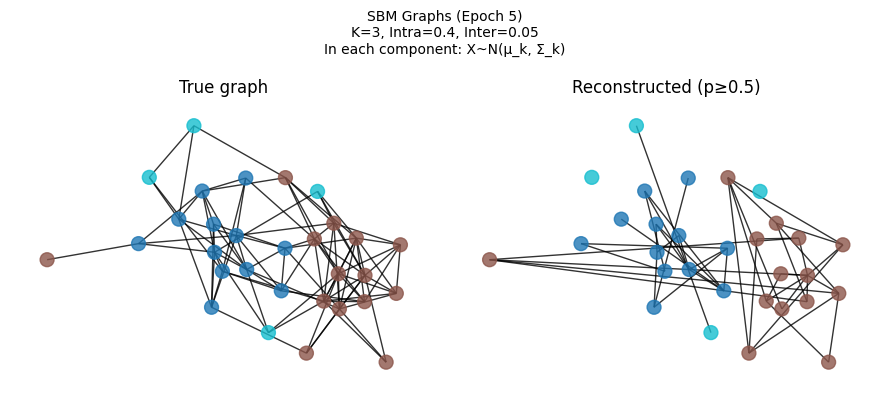

Epoch 006 | Loss: 5994.50 | Recon: 5994.16 | KL: 5.62 | kl_w: 0.06
Epoch 007 | Loss: 5934.94 | Recon: 5934.58 | KL: 5.19 | kl_w: 0.07
Epoch 008 | Loss: 5907.18 | Recon: 5906.85 | KL: 4.07 | kl_w: 0.08
Epoch 009 | Loss: 5896.39 | Recon: 5896.09 | KL: 3.33 | kl_w: 0.09
Epoch 010 | Loss: 5883.06 | Recon: 5882.76 | KL: 2.95 | kl_w: 0.10


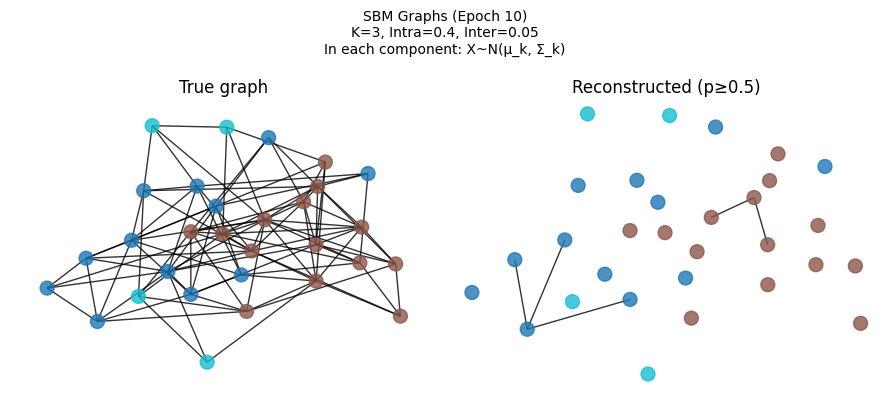

Epoch 011 | Loss: 5868.33 | Recon: 5868.04 | KL: 2.70 | kl_w: 0.11
Epoch 012 | Loss: 5866.19 | Recon: 5865.88 | KL: 2.60 | kl_w: 0.12
Epoch 013 | Loss: 5854.44 | Recon: 5854.10 | KL: 2.59 | kl_w: 0.13
Epoch 014 | Loss: 5848.22 | Recon: 5847.86 | KL: 2.53 | kl_w: 0.14
Epoch 015 | Loss: 5847.57 | Recon: 5847.19 | KL: 2.58 | kl_w: 0.15


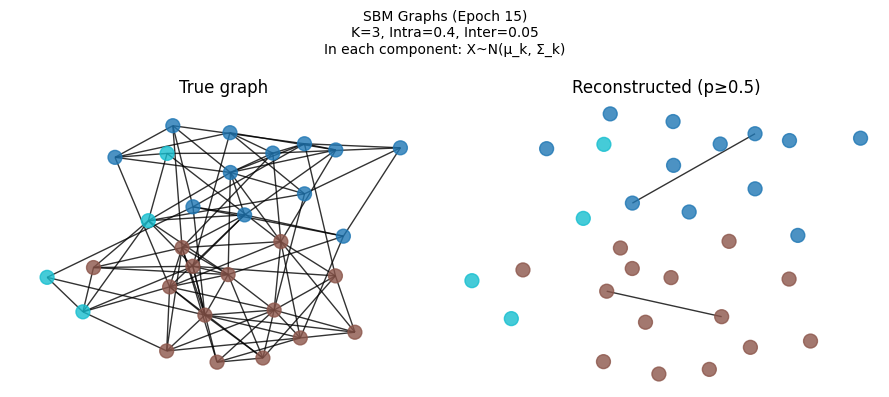

Epoch 016 | Loss: 5850.20 | Recon: 5849.79 | KL: 2.57 | kl_w: 0.16
Epoch 017 | Loss: 5838.93 | Recon: 5838.48 | KL: 2.65 | kl_w: 0.17
Epoch 018 | Loss: 5830.32 | Recon: 5829.84 | KL: 2.69 | kl_w: 0.18
Epoch 019 | Loss: 5830.91 | Recon: 5830.38 | KL: 2.78 | kl_w: 0.19
Epoch 020 | Loss: 5829.36 | Recon: 5828.81 | KL: 2.78 | kl_w: 0.20


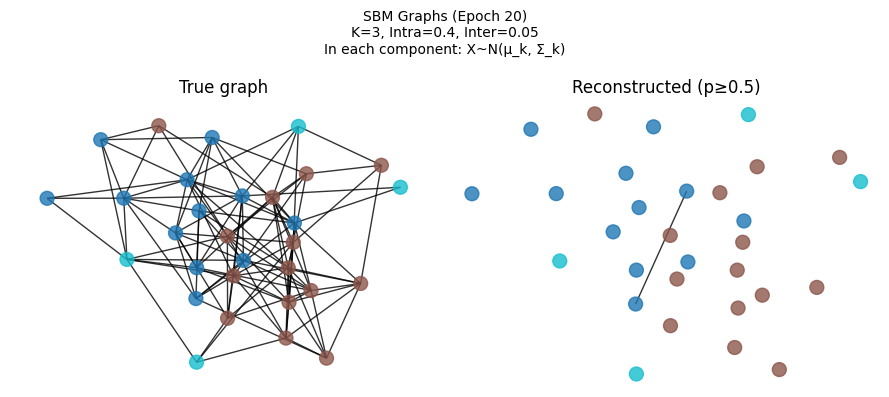

Epoch 021 | Loss: 5829.79 | Recon: 5829.19 | KL: 2.87 | kl_w: 0.21
Epoch 022 | Loss: 5827.23 | Recon: 5826.58 | KL: 2.95 | kl_w: 0.22
Epoch 023 | Loss: 5817.62 | Recon: 5816.94 | KL: 2.99 | kl_w: 0.23
Epoch 024 | Loss: 5816.48 | Recon: 5815.73 | KL: 3.13 | kl_w: 0.24
Epoch 025 | Loss: 5819.56 | Recon: 5818.75 | KL: 3.23 | kl_w: 0.25


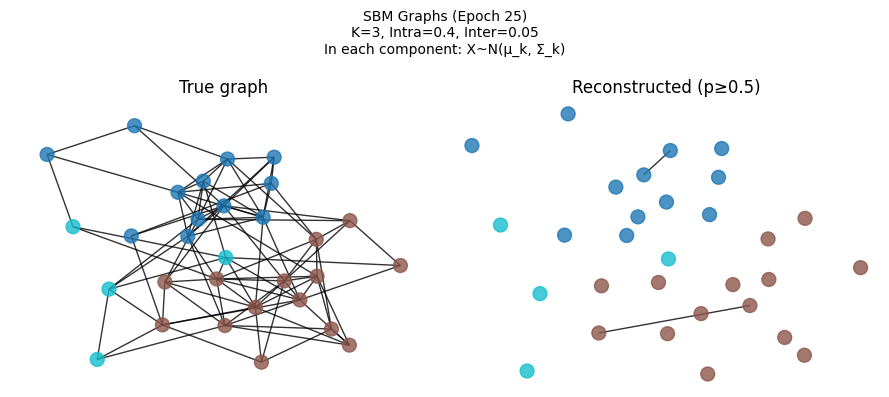

Epoch 026 | Loss: 5814.57 | Recon: 5813.71 | KL: 3.28 | kl_w: 0.26
Epoch 027 | Loss: 5812.02 | Recon: 5811.09 | KL: 3.45 | kl_w: 0.27
Epoch 028 | Loss: 5806.74 | Recon: 5805.74 | KL: 3.56 | kl_w: 0.28
Epoch 029 | Loss: 5808.13 | Recon: 5807.06 | KL: 3.70 | kl_w: 0.29
Epoch 030 | Loss: 5808.70 | Recon: 5807.51 | KL: 3.99 | kl_w: 0.30


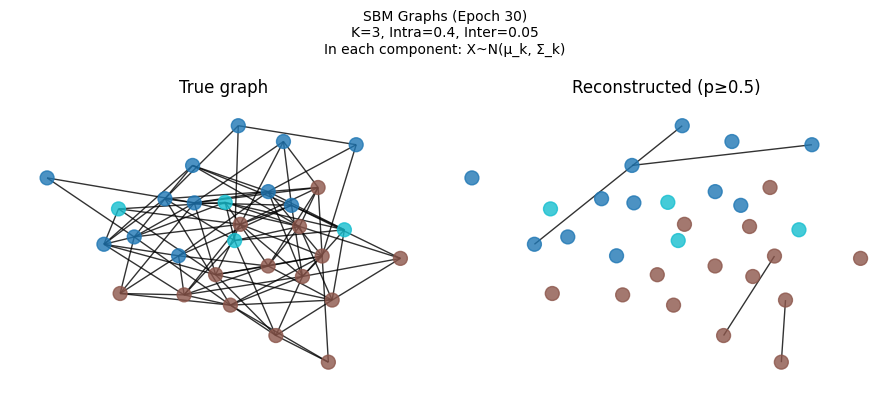

Epoch 031 | Loss: 5804.48 | Recon: 5803.17 | KL: 4.22 | kl_w: 0.31
Epoch 032 | Loss: 5802.43 | Recon: 5801.00 | KL: 4.45 | kl_w: 0.32
Epoch 033 | Loss: 5804.62 | Recon: 5803.13 | KL: 4.52 | kl_w: 0.33
Epoch 034 | Loss: 5795.49 | Recon: 5793.92 | KL: 4.62 | kl_w: 0.34
Epoch 035 | Loss: 5797.61 | Recon: 5795.94 | KL: 4.78 | kl_w: 0.35


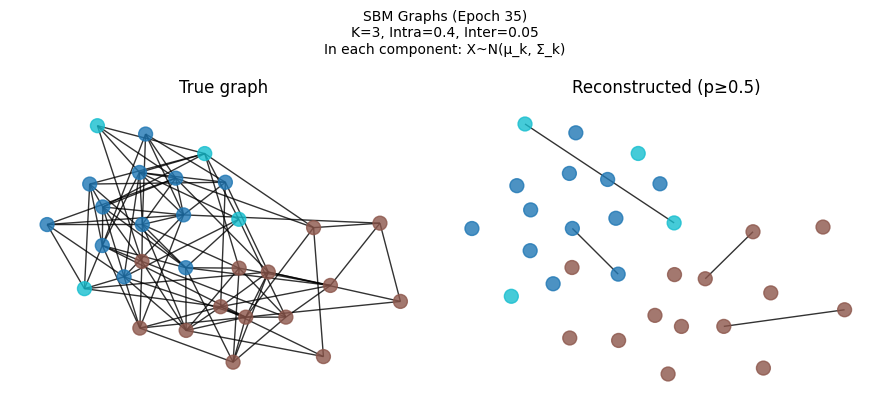

Epoch 036 | Loss: 5795.30 | Recon: 5793.51 | KL: 4.96 | kl_w: 0.36
Epoch 037 | Loss: 5797.60 | Recon: 5795.73 | KL: 5.05 | kl_w: 0.37
Epoch 038 | Loss: 5789.87 | Recon: 5787.97 | KL: 4.99 | kl_w: 0.38
Epoch 039 | Loss: 5794.44 | Recon: 5792.46 | KL: 5.09 | kl_w: 0.39
Epoch 040 | Loss: 5790.90 | Recon: 5788.95 | KL: 4.87 | kl_w: 0.40


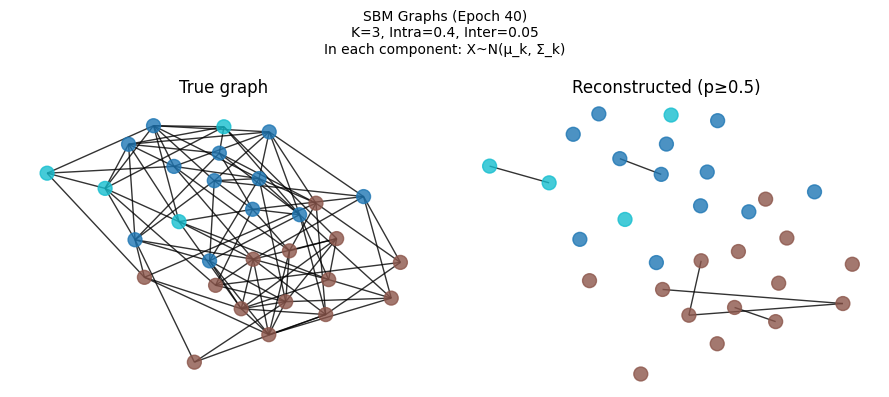

Epoch 041 | Loss: 5791.24 | Recon: 5789.32 | KL: 4.68 | kl_w: 0.41
Epoch 042 | Loss: 5784.69 | Recon: 5782.75 | KL: 4.63 | kl_w: 0.42
Epoch 043 | Loss: 5791.85 | Recon: 5789.86 | KL: 4.64 | kl_w: 0.43
Epoch 044 | Loss: 5782.88 | Recon: 5780.81 | KL: 4.72 | kl_w: 0.44
Epoch 045 | Loss: 5777.26 | Recon: 5775.13 | KL: 4.73 | kl_w: 0.45


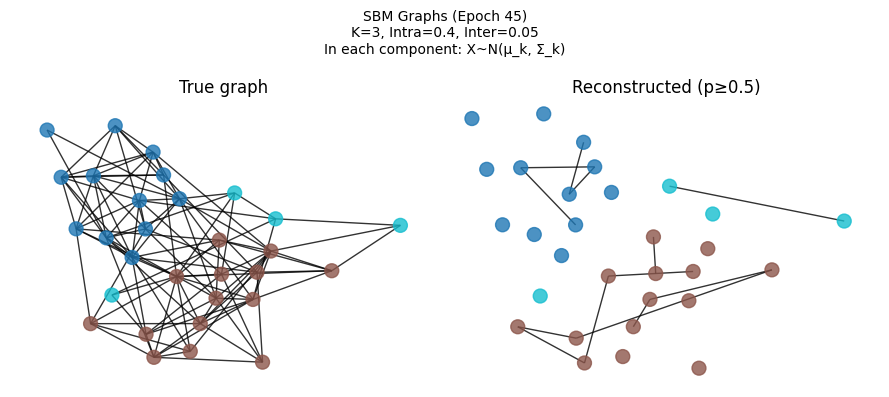

Epoch 046 | Loss: 5782.37 | Recon: 5780.14 | KL: 4.83 | kl_w: 0.46
Epoch 047 | Loss: 5784.49 | Recon: 5782.22 | KL: 4.84 | kl_w: 0.47
Epoch 048 | Loss: 5779.33 | Recon: 5776.99 | KL: 4.86 | kl_w: 0.48
Epoch 049 | Loss: 5782.72 | Recon: 5780.29 | KL: 4.95 | kl_w: 0.49
Epoch 050 | Loss: 5780.62 | Recon: 5778.10 | KL: 5.05 | kl_w: 0.50


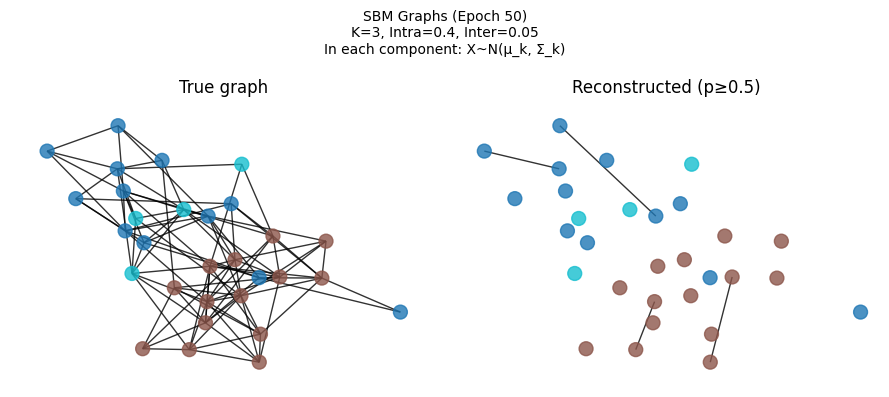

Epoch 051 | Loss: 5774.12 | Recon: 5771.51 | KL: 5.12 | kl_w: 0.51
Epoch 052 | Loss: 5775.10 | Recon: 5772.46 | KL: 5.09 | kl_w: 0.52
Epoch 053 | Loss: 5775.67 | Recon: 5772.89 | KL: 5.25 | kl_w: 0.53
Epoch 054 | Loss: 5778.83 | Recon: 5775.99 | KL: 5.25 | kl_w: 0.54
Epoch 055 | Loss: 5780.46 | Recon: 5777.53 | KL: 5.33 | kl_w: 0.55


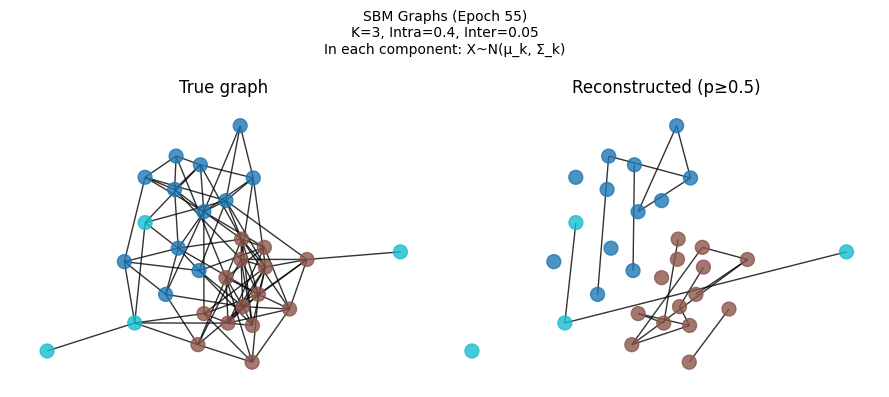

Epoch 056 | Loss: 5777.23 | Recon: 5774.20 | KL: 5.42 | kl_w: 0.56
Epoch 057 | Loss: 5777.13 | Recon: 5774.08 | KL: 5.34 | kl_w: 0.57
Epoch 058 | Loss: 5775.24 | Recon: 5772.16 | KL: 5.31 | kl_w: 0.58
Epoch 059 | Loss: 5771.89 | Recon: 5768.75 | KL: 5.32 | kl_w: 0.59
Epoch 060 | Loss: 5765.88 | Recon: 5762.70 | KL: 5.31 | kl_w: 0.60


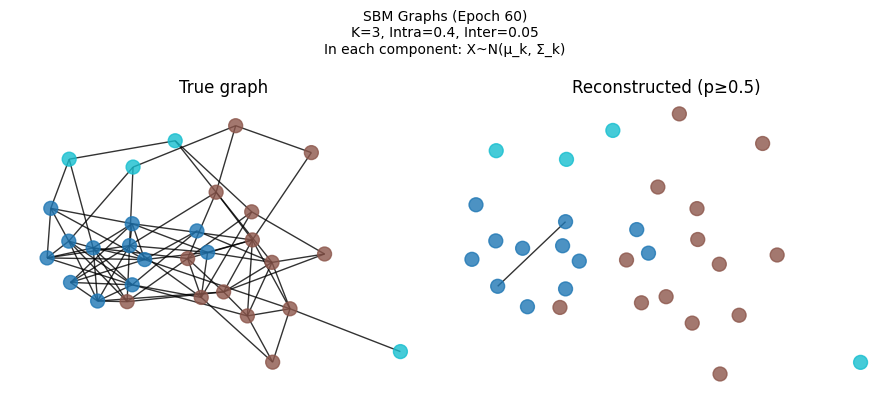

Epoch 061 | Loss: 5776.05 | Recon: 5772.72 | KL: 5.45 | kl_w: 0.61
Epoch 062 | Loss: 5767.54 | Recon: 5764.13 | KL: 5.49 | kl_w: 0.62
Epoch 063 | Loss: 5767.34 | Recon: 5763.97 | KL: 5.36 | kl_w: 0.63
Epoch 064 | Loss: 5772.72 | Recon: 5769.19 | KL: 5.52 | kl_w: 0.64
Epoch 065 | Loss: 5769.30 | Recon: 5765.76 | KL: 5.45 | kl_w: 0.65


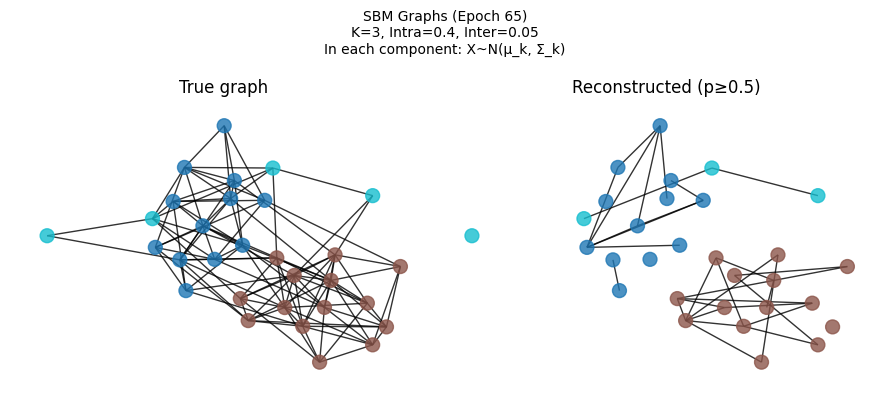

Epoch 066 | Loss: 5773.86 | Recon: 5770.20 | KL: 5.55 | kl_w: 0.66
Epoch 067 | Loss: 5774.39 | Recon: 5770.70 | KL: 5.50 | kl_w: 0.67
Epoch 068 | Loss: 5774.13 | Recon: 5770.42 | KL: 5.46 | kl_w: 0.68
Epoch 069 | Loss: 5775.37 | Recon: 5771.59 | KL: 5.48 | kl_w: 0.69
Epoch 070 | Loss: 5771.50 | Recon: 5767.67 | KL: 5.47 | kl_w: 0.70


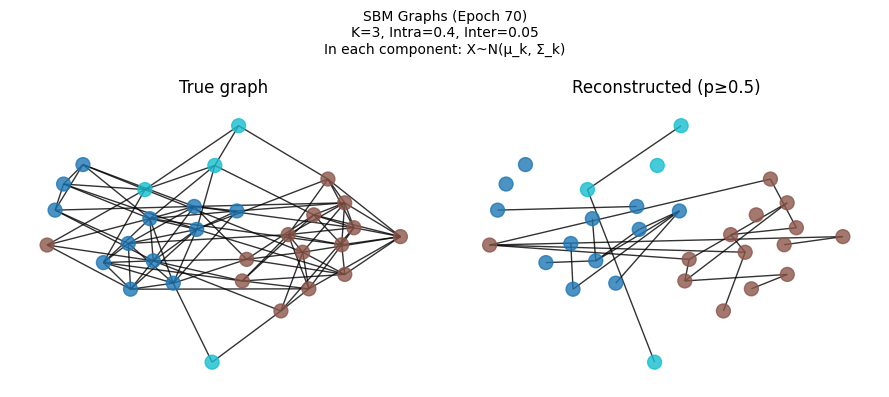

Epoch 071 | Loss: 5769.39 | Recon: 5765.53 | KL: 5.44 | kl_w: 0.71
Epoch 072 | Loss: 5772.28 | Recon: 5768.42 | KL: 5.36 | kl_w: 0.72
Epoch 073 | Loss: 5771.37 | Recon: 5767.49 | KL: 5.31 | kl_w: 0.73
Epoch 074 | Loss: 5772.39 | Recon: 5768.43 | KL: 5.36 | kl_w: 0.74
Epoch 075 | Loss: 5769.68 | Recon: 5765.64 | KL: 5.38 | kl_w: 0.75


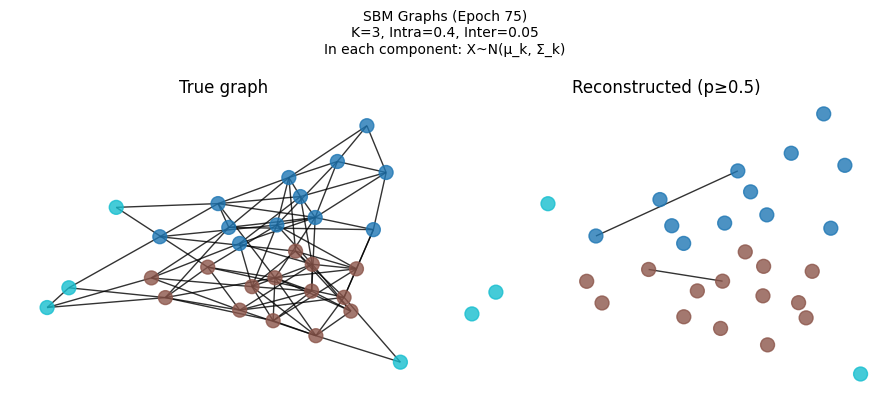

Epoch 076 | Loss: 5758.13 | Recon: 5754.05 | KL: 5.37 | kl_w: 0.76
Epoch 077 | Loss: 5766.28 | Recon: 5762.16 | KL: 5.34 | kl_w: 0.77
Epoch 078 | Loss: 5765.02 | Recon: 5760.86 | KL: 5.33 | kl_w: 0.78
Epoch 079 | Loss: 5766.59 | Recon: 5762.37 | KL: 5.34 | kl_w: 0.79
Epoch 080 | Loss: 5765.09 | Recon: 5760.77 | KL: 5.40 | kl_w: 0.80


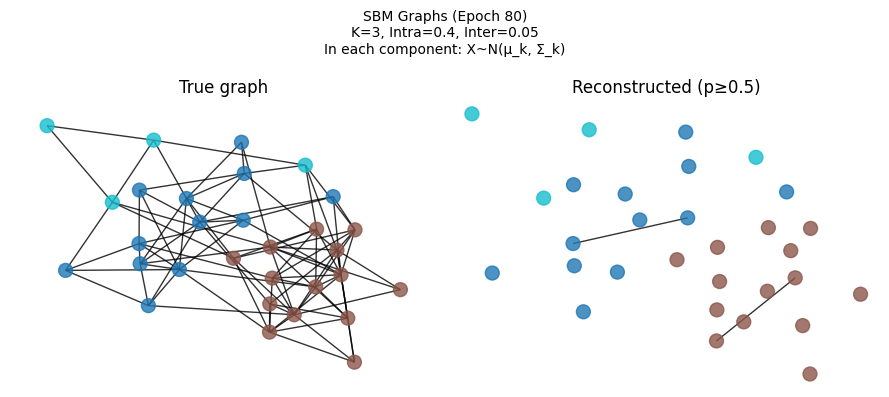

Epoch 081 | Loss: 5765.23 | Recon: 5760.80 | KL: 5.48 | kl_w: 0.81
Epoch 082 | Loss: 5762.30 | Recon: 5757.87 | KL: 5.40 | kl_w: 0.82
Epoch 083 | Loss: 5769.44 | Recon: 5764.98 | KL: 5.38 | kl_w: 0.83
Epoch 084 | Loss: 5764.81 | Recon: 5760.30 | KL: 5.37 | kl_w: 0.84
Epoch 085 | Loss: 5768.78 | Recon: 5764.09 | KL: 5.51 | kl_w: 0.85


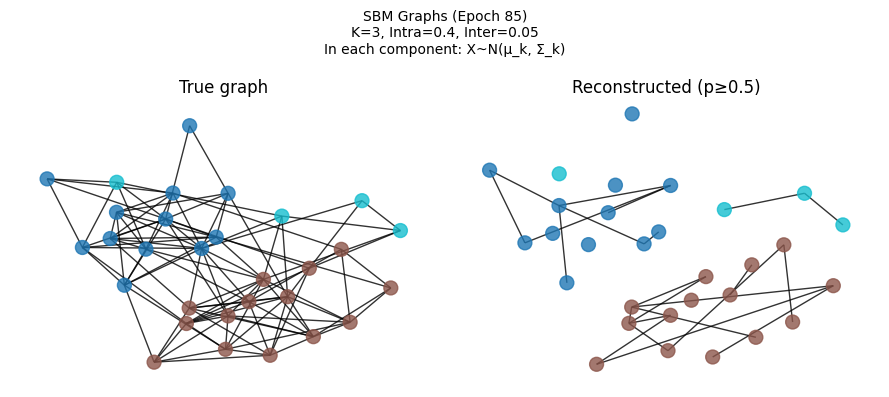

Epoch 086 | Loss: 5764.84 | Recon: 5760.11 | KL: 5.51 | kl_w: 0.86
Epoch 087 | Loss: 5767.94 | Recon: 5763.08 | KL: 5.59 | kl_w: 0.87
Epoch 088 | Loss: 5775.22 | Recon: 5770.46 | KL: 5.41 | kl_w: 0.88
Epoch 089 | Loss: 5766.33 | Recon: 5761.57 | KL: 5.35 | kl_w: 0.89
Epoch 090 | Loss: 5770.91 | Recon: 5766.19 | KL: 5.24 | kl_w: 0.90


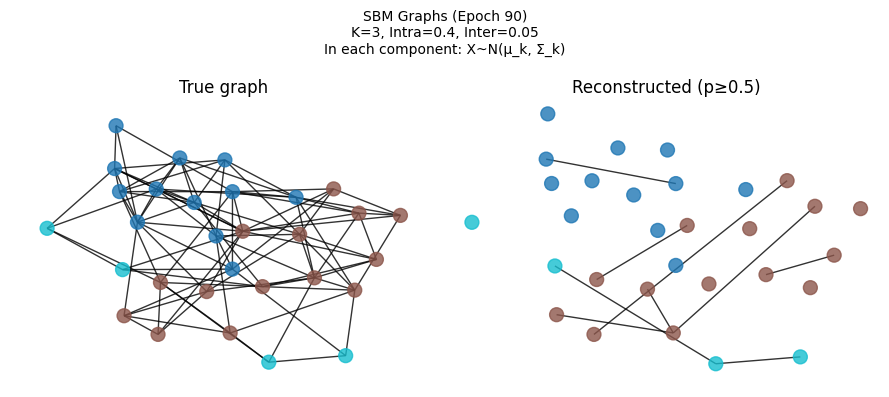

Epoch 091 | Loss: 5764.92 | Recon: 5760.20 | KL: 5.19 | kl_w: 0.91
Epoch 092 | Loss: 5760.03 | Recon: 5755.19 | KL: 5.26 | kl_w: 0.92
Epoch 093 | Loss: 5763.65 | Recon: 5758.78 | KL: 5.24 | kl_w: 0.93
Epoch 094 | Loss: 5761.65 | Recon: 5756.73 | KL: 5.24 | kl_w: 0.94
Epoch 095 | Loss: 5760.71 | Recon: 5755.72 | KL: 5.25 | kl_w: 0.95


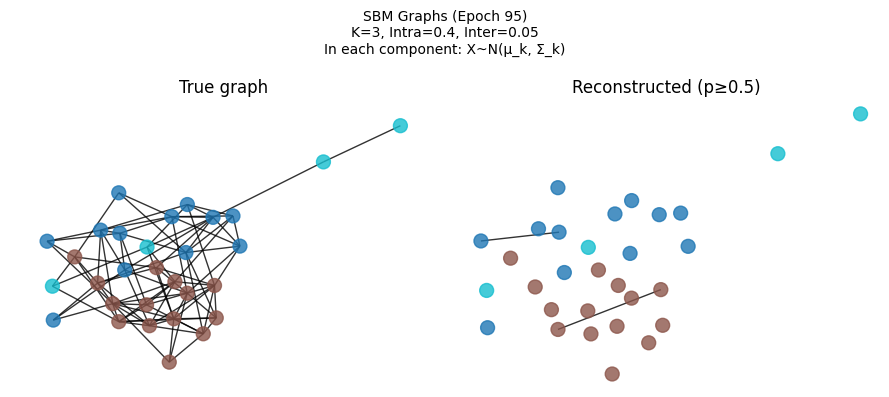

Epoch 096 | Loss: 5758.54 | Recon: 5753.57 | KL: 5.18 | kl_w: 0.96
Epoch 097 | Loss: 5773.00 | Recon: 5767.98 | KL: 5.17 | kl_w: 0.97
Epoch 098 | Loss: 5762.68 | Recon: 5757.58 | KL: 5.21 | kl_w: 0.98
Epoch 099 | Loss: 5757.99 | Recon: 5752.83 | KL: 5.22 | kl_w: 0.99
Epoch 100 | Loss: 5768.16 | Recon: 5762.96 | KL: 5.20 | kl_w: 1.00


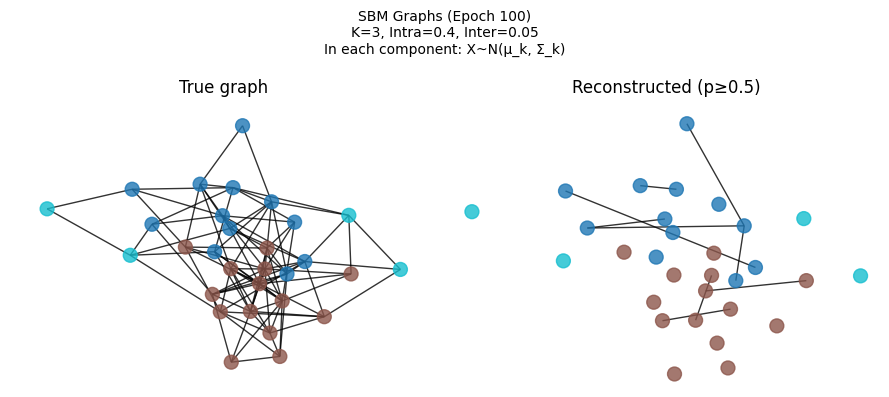


 Model saved: temporal_graph_vae_sbm.pth
Sample 1 | Edge match accuracy: 78.62%


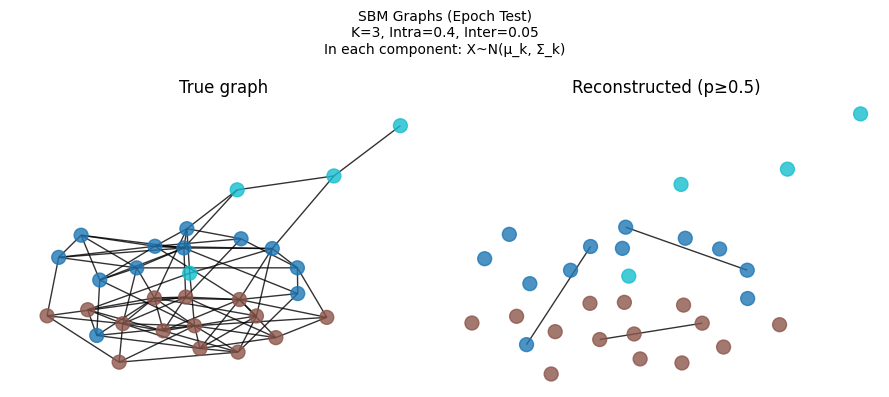

Sample 2 | Edge match accuracy: 79.08%


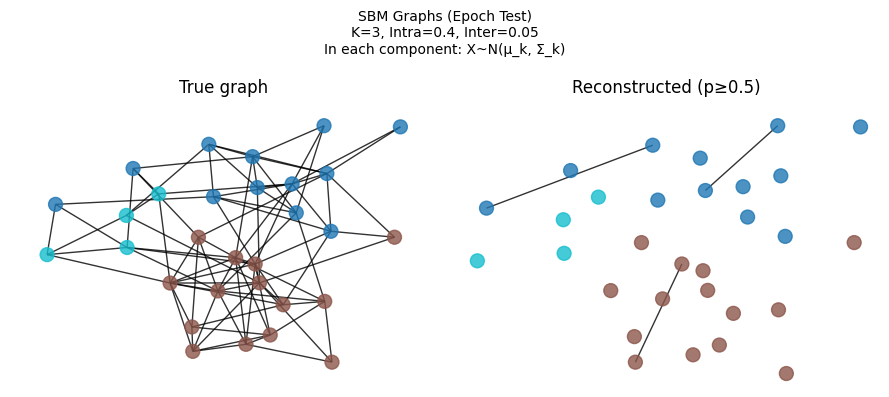

Sample 3 | Edge match accuracy: 76.55%


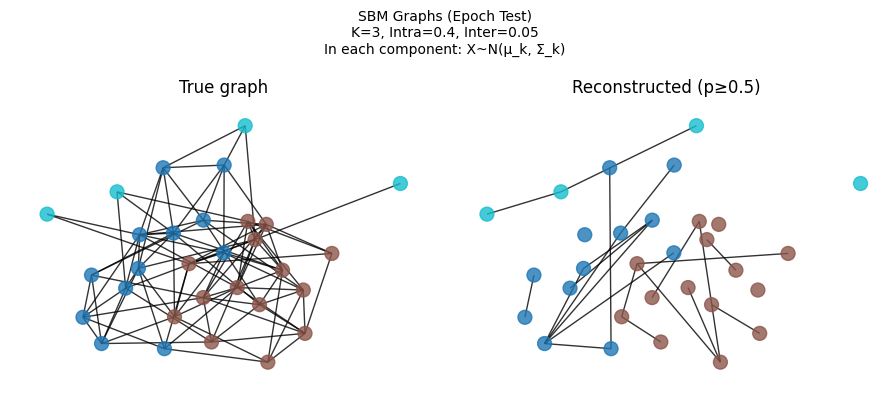

Sample 4 | Edge match accuracy: 77.70%


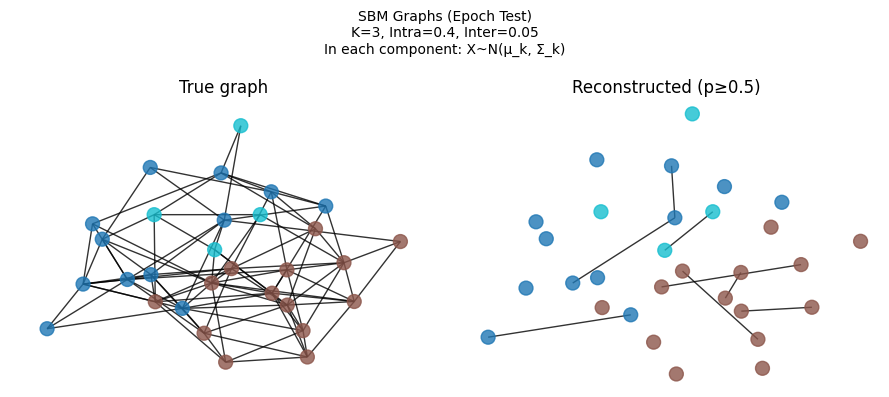

Sample 5 | Edge match accuracy: 77.70%


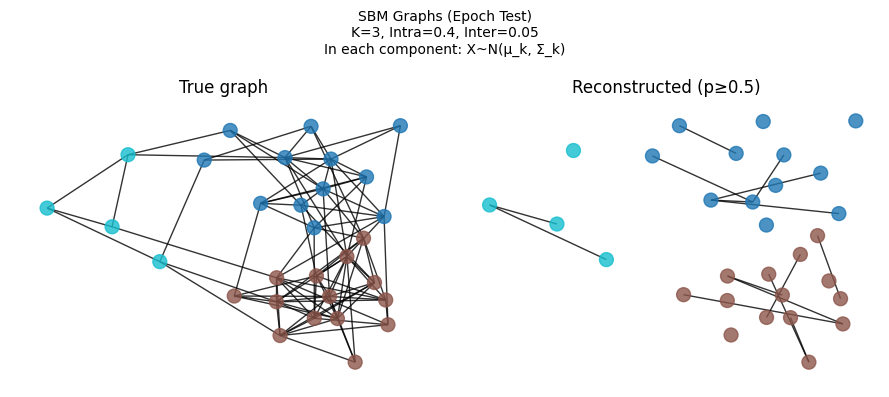


Test accuracy (edge match): 77.93%


In [9]:

if __name__ == "__main__":
    model, dataset = train_model(vis_interval=5, epochs=100)
    test_model(model, dataset)


# Question 2: Conditional Variational Autoencoder (CVAE) for Digit Generation

This note introduces a **Conditional Variational Autoencoder (CVAE)** for image generation on the **MNIST** dataset. The goal is to learn a deep latent-variable model that can synthesize digits conditioned on a desired label—e.g., generate a “2” on demand—and optionally modulate the writing style.


## **Problem setup**

We observe training pairs of handwritten digits and their class labels
$$
\mathcal{D} = {(x^{(i)}, y^{(i)})}_{i=1}^N,
$$
where $x^{(i)} \in \mathbb{R}^{28\times28}$ is an image and $y^{(i)} \in {0,\dots,9}$ is the corresponding digit label.
Our goal is to model the conditional data distribution
$$
p_\theta(x \mid y),
$$
so that, given any label $y$, the model can generate realistic samples $x$ of that digit.



In [1]:
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

### **Model setup**

We introduce a latent variable $ z \in \mathbb{R}^m $ that captures continuous variations in handwriting style.
The joint distribution is defined as

$$
p_\theta(x, z \mid y) = p_\theta(x \mid z, y) p(z),
$$

where $ p(z) = \mathcal{N}(0, I) $ is a fixed Gaussian prior.

* **Decoder (generative model):** $ p_\theta(x \mid z, y) $ reconstructs the image given latent code $z$ and label $y$.
* **Encoder (inference model):** we approximate the true posterior $ p_\theta(z \mid x, y) $ with

$$
q_\phi(z \mid x, y) = \mathcal{N}\big(\mu_\phi(x, y), \mathrm{diag}(\sigma_\phi^2(x, y))\big).
$$



### **Derivation of the Conditional ELBO**

Our goal is to maximize the conditional log-likelihood of the data:

$$
\log p_\theta(x \mid y).
$$

Since this is intractable, we derive a lower bound (the **conditional ELBO**):

$$
\log p_\theta(x \mid y)
\ge
\mathbb{E}_{q_\phi(z \mid x, y)}[\log p_\theta(x \mid z, y)]

D_{\mathrm{KL}}\big(q_\phi(z \mid x, y) | p(z)\big).
$$

### **Training objective**

The right-hand side is the objective we actually optimize.
We **maximize** the ELBO with respect to parameters $\theta$ and $\phi$, or equivalently, **minimize** the negative ELBO (which is used as the loss in code):

$$
\mathcal{L}_{\text{CVAE}}(x, y)
= -\mathbb{E}_{q_\phi(z \mid x, y)}[\log p_\theta(x \mid z, y)]
+ D_{\mathrm{KL}}\big(q_\phi(z \mid x, y) | p(z)\big).
$$

- The first term (reconstruction loss) ensures that decoded samples resemble the input image.
- The second term (KL divergence) regularizes the latent distribution so that it stays close to the Gaussian prior, which keeps sampling stable during generation.




In [3]:
class Encoder(nn.Module):
    def __init__(self, x_dim, y_dim, z_dim):
        super().__init__()
        self.x_dim = x_dim
        self.y_dim = y_dim
        self.z_dim = z_dim

        self.fc1 = nn.Linear(x_dim + y_dim, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 128)
        self.fc_mu = nn.Linear(128, z_dim)
        self.fc_logvar = nn.Linear(128, z_dim)

    def forward(self, x, y):
        h = torch.cat([x, y], dim=-1)

        h = F.relu(self.fc1(h))
        h = F.relu(self.fc2(h))
        h = F.relu(self.fc3(h))

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        return mu, logvar

class Decoder(nn.Module):
    def __init__(self, x_dim, y_dim, z_dim):
        super().__init__()
        self.x_dim = x_dim
        self.y_dim = y_dim
        self.z_dim = z_dim

        self.fc1 = nn.Linear(z_dim + y_dim, 128)
        self.fc2 = nn.Linear(128, 256)
        self.fc3 = nn.Linear(256, 512)
        self.fc_x_logits = nn.Linear(512, x_dim)

    def forward(self, z, y):
        h = torch.cat([z, y], dim=-1)
        h = F.relu(self.fc1(h))
        h = F.relu(self.fc2(h))
        h = F.relu(self.fc3(h))

        logits_x = self.fc_x_logits(h)
        return logits_x


class CVAE(nn.Module):
    def __init__(self, x_dim, y_dim, z_dim):
        super().__init__()
        self.encoder = Encoder(x_dim, y_dim, z_dim)
        self.decoder = Decoder(x_dim, y_dim, z_dim)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x, y):
        y_onehot = F.one_hot(y, num_classes=y_dim).float()
        
        mu, logvar = self.encoder(x, y_onehot)
        z = self.reparameterize(mu, logvar)

        logits_x = self.decoder(z, y_onehot)

        return logits_x, mu, logvar

In [4]:
def loss_function(x_recon, x, mu, logvar):
    x_flat = x.view(x.size(0), -1)
    
    recon_loss = F.binary_cross_entropy_with_logits(x_recon, x_flat, reduction='sum') / x.size(0)
    
    kl_div = 0.5 * torch.sum(torch.exp(logvar) + mu**2 - 1. - logvar, dim=1)
    kl_loss = torch.mean(kl_div)
    
    total_loss = recon_loss + kl_loss
    return total_loss, recon_loss, kl_loss

In [5]:
from torch import optim

batch_size = 32
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1))
])
train_dataset = datasets.MNIST('./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'device: {device}')

x_dim = 28*28
y_dim = 10
z_dim = 64
model = CVAE(x_dim=x_dim, y_dim=y_dim, z_dim=z_dim).to(device)

LEARNING_RATE = 1e-3
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

epochs = 20
### don't edit this !!!
for epoch in range(1, epochs+1):
    model.train()
    total_loss = 0.0
    total_recon = 0.0
    total_kl = 0.0
    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()
        x_recon, mu, logvar = model(x, y)

        loss, recon_loss, kl_loss = loss_function(x_recon, x, mu, logvar)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()

    n = len(train_loader.dataset)
    print(f"Epoch {epoch:02d}  Loss per example: {total_loss / n:.4f}  Recon: {total_recon / n:.4f}  KL: {total_kl / n:.4f}")


100%|██████████| 9.91M/9.91M [00:00<00:00, 40.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.05MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.59MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.52MB/s]


device: cuda
Epoch 01  Loss per example: 4.8513  Recon: 4.6424  KL: 0.2089
Epoch 02  Loss per example: 3.8490  Recon: 3.5623  KL: 0.2867
Epoch 03  Loss per example: 3.6770  Recon: 3.3804  KL: 0.2966
Epoch 04  Loss per example: 3.5881  Recon: 3.2861  KL: 0.3021
Epoch 05  Loss per example: 3.5341  Recon: 3.2291  KL: 0.3050
Epoch 06  Loss per example: 3.5010  Recon: 3.1934  KL: 0.3075
Epoch 07  Loss per example: 3.4721  Recon: 3.1635  KL: 0.3085
Epoch 08  Loss per example: 3.4516  Recon: 3.1411  KL: 0.3105
Epoch 09  Loss per example: 3.4349  Recon: 3.1238  KL: 0.3112
Epoch 10  Loss per example: 3.4190  Recon: 3.1073  KL: 0.3116
Epoch 11  Loss per example: 3.4066  Recon: 3.0933  KL: 0.3134
Epoch 12  Loss per example: 3.3953  Recon: 3.0806  KL: 0.3147
Epoch 13  Loss per example: 3.3843  Recon: 3.0688  KL: 0.3154
Epoch 14  Loss per example: 3.3755  Recon: 3.0596  KL: 0.3159
Epoch 15  Loss per example: 3.3665  Recon: 3.0501  KL: 0.3164
Epoch 16  Loss per example: 3.3612  Recon: 3.0433  KL: 0.

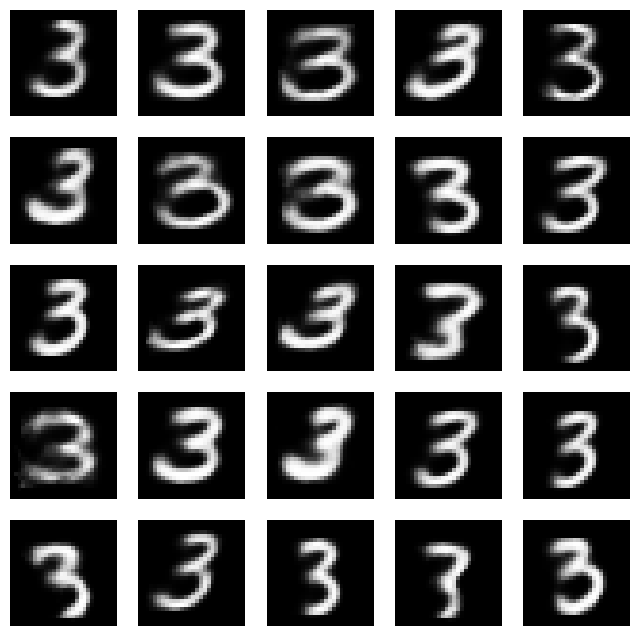

In [39]:
# model inferencing
model.eval()
with torch.no_grad():
    digit = 3
    n = 25
    y = torch.full((n,), digit, dtype=torch.long).to(device)
    y_onehot = F.one_hot(y, num_classes=model.decoder.y_dim).float().to(device)

    z = torch.randn(n, z_dim).to(device)

    logits_x = model.decoder(z, y_onehot)
    x_gen = torch.sigmoid(logits_x).cpu()

# visualize
x_gen = x_gen.view(n, 1, 28, 28)

plt.figure(figsize=(8, 8))
for i in range(n):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x_gen[i, 0], cmap='gray')
    plt.axis('off')


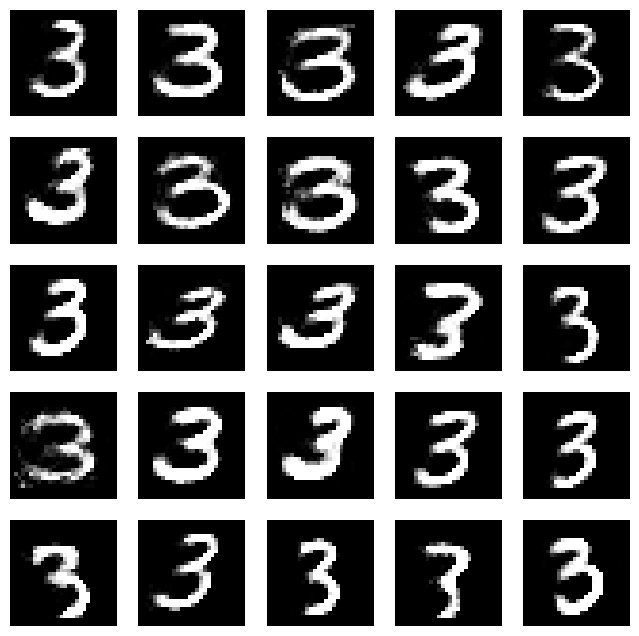

In [40]:
import numpy as np
from scipy.signal import convolve2d

sharpen_kernel = np.array([[0, -1, 0],
                           [-1, 5, -1],
                           [0, -1, 0]])

plt.figure(figsize=(8, 8))
for i in range(n):
    sharpened_img = convolve2d(x_gen[i, 0], sharpen_kernel, mode='same', boundary='symm')
    sharpened_img = np.clip(sharpened_img, 0, 1)
    
    plt.subplot(5, 5, i + 1)
    plt.imshow(sharpened_img, cmap='gray')
    plt.axis('off')

### Student ID Generation
After training your CVAE model, define a function that takes your 9-digit student ID as input and generates one digit per number in your ID. Each digit must be conditioned on its corresponding label (0–9). Arrange the generated digits horizontally in a 1×9 grid to visually display your complete student ID as a sequence of generated MNIST-style digits. Include this final generated image in your report.

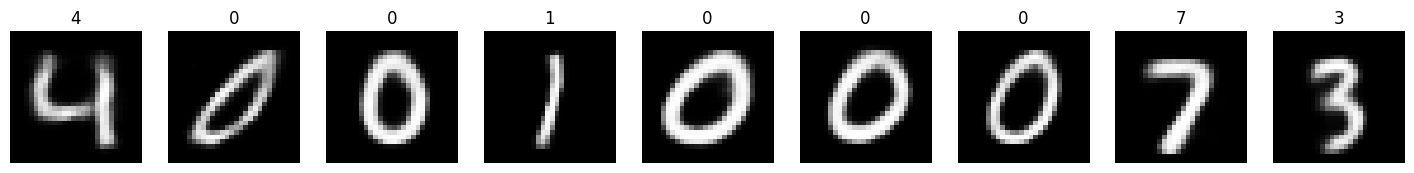

In [35]:
def generate_student_digits(model, student_id, device='cpu'):
    digits = [int(d) for d in str(student_id)]
    y = torch.tensor(digits, dtype=torch.long, device=device)
    y_onehot = F.one_hot(y, num_classes=10).float()
    
    z = torch.randn(len(digits), 64).to(device)

    logits_x = model.decoder(z, y_onehot)
    x_gen = torch.sigmoid(logits_x).cpu()
    x_gen = x_gen.view(len(digits), 1, 28, 28)
    
    plt.figure(figsize=(2*len(digits), 2))
    for i in range(len(digits)):
        plt.subplot(1, len(digits), i + 1)
        plt.imshow(x_gen[i, 0].detach().numpy(), cmap='gray')
        plt.title(digits[i])
        plt.axis('off')

generate_student_digits(model, 400100073, device)

### **Latent Space Exploration**
To demonstrate that your CVAE has learned a meaningful latent representation, write a function that visualizes the latent space of the model.
Select **two random latent directions** in $z$-space, fix a target digit label $y$, and generate a **9×9 grid** of samples by varying these two directions from negative to positive values.
The center of the grid should correspond to $z = 0$ (the mean latent vector), while moving along the axes explores different variations of handwriting style.
After visualizing, **describe what each direction appears to represent**—for example, changes in stroke thickness, slant, or digit shape—and discuss whether the transformations look smooth and interpretable.


### **Plot 1**  
Shows a gradual change in **style** and **sharpness** of the digit.

### **Plot 2**  
Shows a gradual change in **digit identity** (transitioning from *6* to *2*) and **stroke thickness** of the digit.

### **Plot 3**  
Shows a gradual change in **stroke thickness** and **style** of the digit.

- - -
### **Plot 4**  
Shows a gradual change in **sharpness** and **style** of the digit.

- - -
### **Plot 5** 
Shows a gradual change in **digit identity** (from *2* to *6*) and **style** of the digit.

- - -
### **Plot 6**  
Shows a gradual change in **style** of the digit.


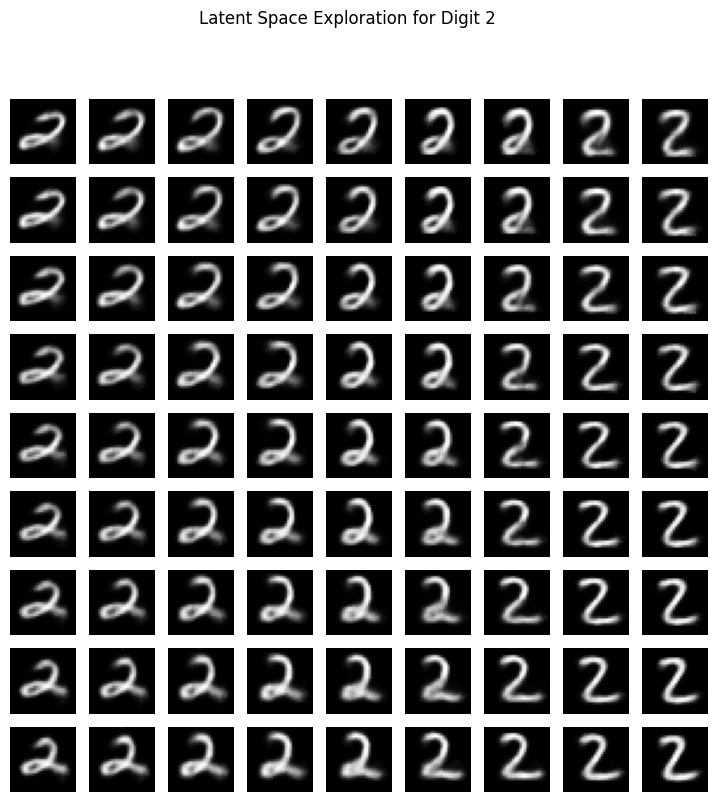

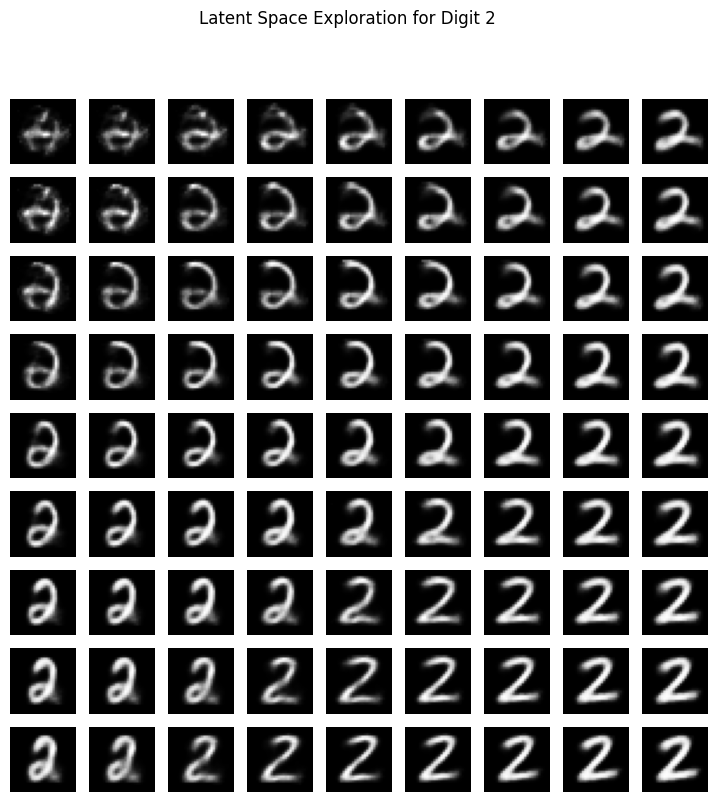

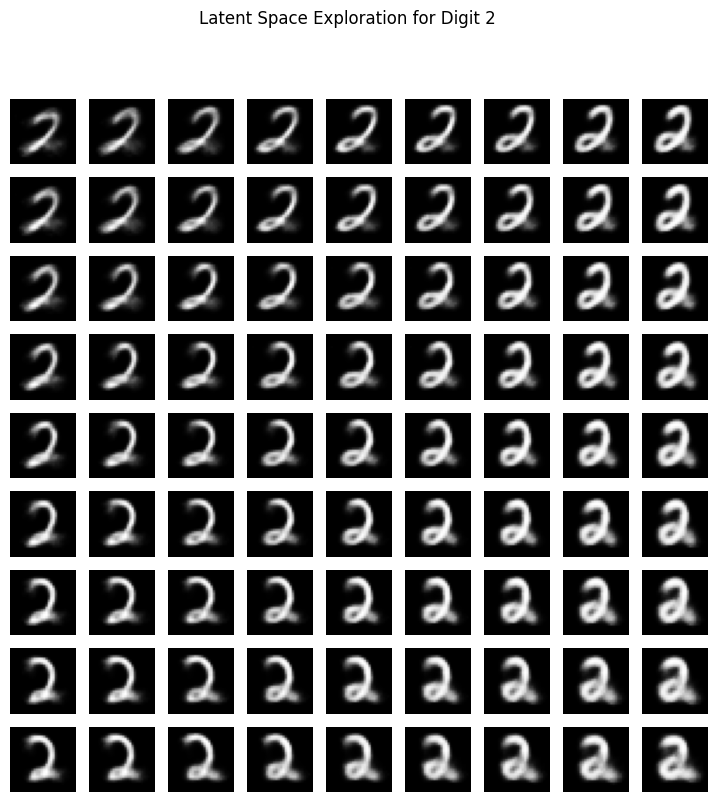

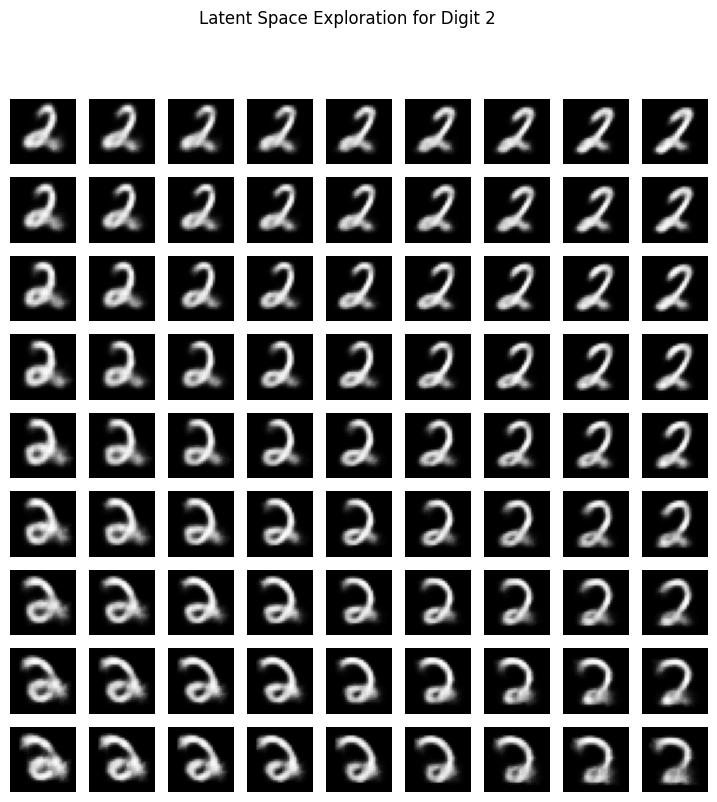

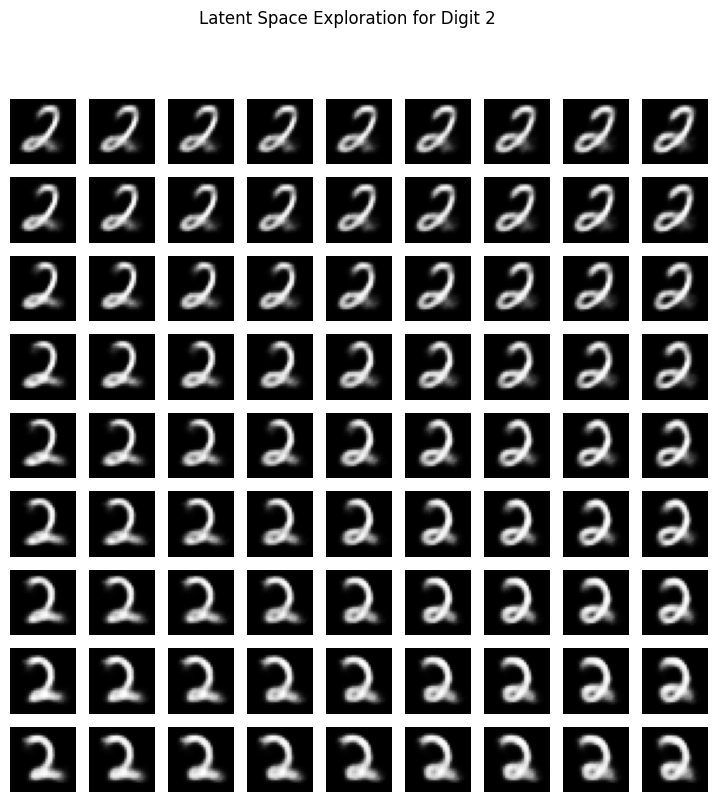

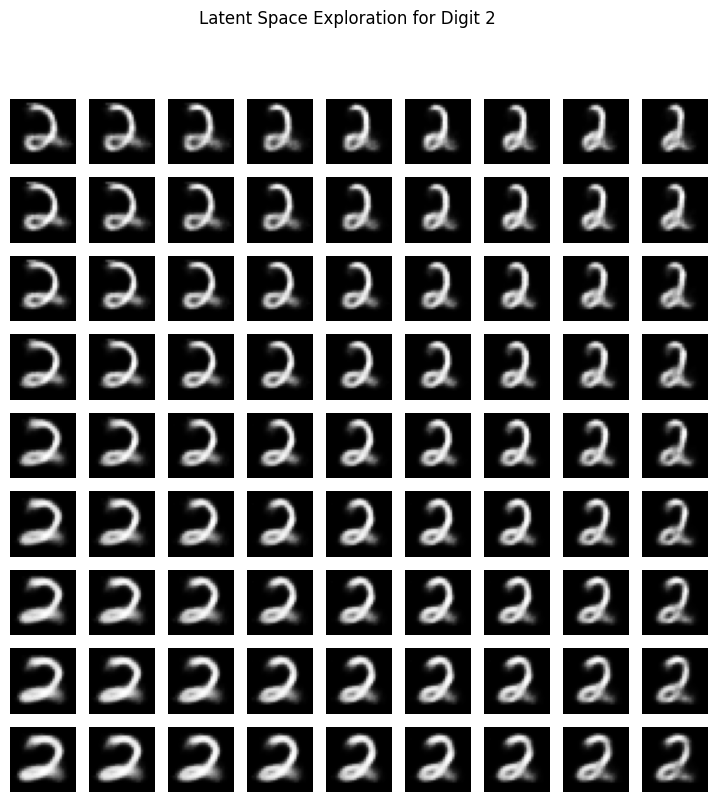

In [46]:
def visualize_latent_space(model, y_label, z_dim=64, grid_size=9, scale=5.0, device='cpu', img_size=28):
    # Move model to device
    model.to(device)
    model.eval()

    # Select two random latent directions
    direction_1 = torch.randn(z_dim, device=device)
    direction_1 /= direction_1.norm()
    direction_2 = torch.randn(z_dim, device=device)
    direction_2 -= (direction_2 @ direction_1) * direction_1
    direction_2 /= direction_2.norm()

    # Grid values
    linspace = torch.linspace(-scale, scale, grid_size, device=device)
    
    # One-hot label on correct device
    y = torch.full((1,), y_label, dtype=torch.long, device=device)
    y_onehot = F.one_hot(y, num_classes=model.decoder.y_dim).float().to(device)

    # Prepare figure
    fig, axes = plt.subplots(grid_size, grid_size, figsize=(grid_size, grid_size))
    
    with torch.no_grad():
        for i, alpha in enumerate(linspace):
            for j, beta in enumerate(linspace):
                z = alpha * direction_1 + beta * direction_2
                z = z.unsqueeze(0)  # batch dim
                x_gen = torch.sigmoid(model.decoder(z, y_onehot))
                
                # Reshape flattened image to 2D
                img = x_gen[0].cpu().numpy()
                if img.ndim == 1:
                    img = img.reshape(img_size, img_size)
                elif img.shape[0] == 1:
                    img = img[0].reshape(img_size, img_size)
                
                axes[i, j].imshow(img, cmap='gray')
                axes[i, j].axis('off')
    
    plt.suptitle(f'Latent Space Exploration for Digit {y_label}')
    plt.show()

visualize_latent_space(model, 2)
visualize_latent_space(model, 2)
visualize_latent_space(model, 2)
visualize_latent_space(model, 2)
visualize_latent_space(model, 2)
visualize_latent_space(model, 2)



### **Bonus – Style-Controlled Student ID Generation**
Extend your CVAE to allow **style control** along a latent dimension.
Write a function that takes your **9-digit student ID** as input and generates one digit per number, arranged in a single row.
Additionally, for each digit, gradually vary the “style” dimension from thin to thick (or light to bold) as you move across the row, so that the same digit shows different styles.
Include the resulting image in your report and briefly describe how the style changes are reflected in the generated digits.


My approach is to split `z` into two part: first one is encoded using both `x` and `y` and the second part is only using `x`. This way, part of `z` is only responsible for style.

In [1]:
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

class ControlledEncoder(nn.Module):
    def __init__(self, x_dim, y_dim, z_dim, z_dim_controlled):
        super().__init__()
        self.x_dim = x_dim
        self.y_dim = y_dim
        self.z_dim = z_dim
        self.z_dim_controlled = z_dim_controlled

        self.fc1 = nn.Linear(x_dim + y_dim, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 128)
        self.fc_mu = nn.Linear(128, z_dim)
        self.fc_logvar = nn.Linear(128, z_dim)

        self.cfc1 = nn.Linear(x_dim, 256)
        self.cfc_mu = nn.Linear(256, z_dim_controlled)
        self.cfc_logvar = nn.Linear(256, z_dim_controlled)

    def forward(self, x, y):
        h = torch.cat([x, y], dim=-1)

        h = F.relu(self.fc1(h))
        h = F.relu(self.fc2(h))
        h = F.relu(self.fc3(h))

        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)

        x_c = F.relu(self.cfc1(x))
        mu_c = self.cfc_mu(x_c)
        logvar_c = self.cfc_logvar(x_c)

        return torch.cat([mu, mu_c], dim=-1), torch.cat([logvar, logvar_c], dim=-1)

class Decoder(nn.Module):
    def __init__(self, x_dim, y_dim, z_dim):
        super().__init__()
        self.x_dim = x_dim
        self.y_dim = y_dim
        self.z_dim = z_dim

        self.fc1 = nn.Linear(z_dim + y_dim, 128)
        self.fc2 = nn.Linear(128, 256)
        self.fc3 = nn.Linear(256, 512)
        self.fc_x_logits = nn.Linear(512, x_dim)

    def forward(self, z, y):
        h = torch.cat([z, y], dim=-1)
        h = F.relu(self.fc1(h))
        h = F.relu(self.fc2(h))
        h = F.relu(self.fc3(h))

        logits_x = self.fc_x_logits(h)
        return logits_x


class ControlledCVAE(nn.Module):
    def __init__(self, x_dim, y_dim, z_dim, z_dim_controlled):
        super().__init__()
        self.x_dim = x_dim
        self.y_dim = y_dim
        self.z_dim = z_dim
        self.z_dim_controlled = z_dim_controlled
        
        self.encoder = ControlledEncoder(x_dim, y_dim, z_dim, z_dim_controlled)
        self.decoder = Decoder(x_dim, y_dim, z_dim+z_dim_controlled)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x, y):
        y_onehot = F.one_hot(y, num_classes=self.y_dim).float()
        
        mu, logvar = self.encoder(x, y_onehot)
        z = self.reparameterize(mu, logvar)

        logits_x = self.decoder(z, y_onehot)

        return logits_x, mu, logvar

In [2]:
def loss_function(x_recon, x, mu, logvar):
    x_flat = x.view(x.size(0), -1)
    
    recon_loss = F.binary_cross_entropy_with_logits(x_recon, x_flat, reduction='sum') / x.size(0)
    
    kl_div = 0.5 * torch.sum(torch.exp(logvar) + mu**2 - 1. - logvar, dim=1)
    kl_loss = torch.mean(kl_div)
    
    total_loss = recon_loss + kl_loss
    return total_loss, recon_loss, kl_loss

In [16]:
from torch import optim

batch_size = 32
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x.view(-1))
])
train_dataset = datasets.MNIST('./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f'device: {device}')

x_dim = 28*28
y_dim = 10
z_dim = 4
z_dim_controlled = 60
model = ControlledCVAE(x_dim=x_dim, y_dim=y_dim, z_dim=z_dim, z_dim_controlled=z_dim_controlled).to(device)

LEARNING_RATE = 1e-3
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

epochs = 10
### don't edit this !!!
for epoch in range(1, epochs+1):
    model.train()
    total_loss = 0.0
    total_recon = 0.0
    total_kl = 0.0
    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()
        x_recon, mu, logvar = model(x, y)

        loss, recon_loss, kl_loss = loss_function(x_recon, x, mu, logvar)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        total_recon += recon_loss.item()
        total_kl += kl_loss.item()

    n = len(train_loader.dataset)
    print(f"Epoch {epoch:02d}  Loss per example: {total_loss / n:.4f}  Recon: {total_recon / n:.4f}  KL: {total_kl / n:.4f}")


device: cuda
Epoch 01  Loss per example: 4.7364  Recon: 4.4290  KL: 0.3074
Epoch 02  Loss per example: 3.6680  Recon: 3.2330  KL: 0.4349
Epoch 03  Loss per example: 3.4744  Recon: 3.0115  KL: 0.4629
Epoch 04  Loss per example: 3.3835  Recon: 2.9078  KL: 0.4757
Epoch 05  Loss per example: 3.3277  Recon: 2.8443  KL: 0.4834
Epoch 06  Loss per example: 3.2896  Recon: 2.8004  KL: 0.4892
Epoch 07  Loss per example: 3.2629  Recon: 2.7705  KL: 0.4924
Epoch 08  Loss per example: 3.2414  Recon: 2.7442  KL: 0.4971
Epoch 09  Loss per example: 3.2195  Recon: 2.7178  KL: 0.5018
Epoch 10  Loss per example: 3.2028  Recon: 2.6981  KL: 0.5047


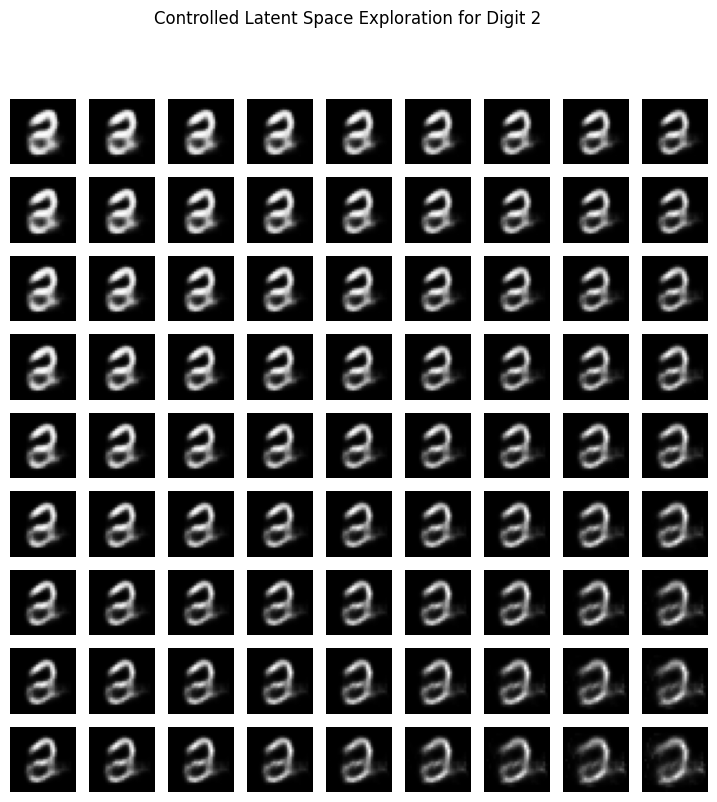

In [21]:
def visualize_latent_space_controlled(model, y_label, grid_size=9, scale=3.0, device='cpu', img_size=28):
    model.to(device)
    model.eval()

    z_dim = model.z_dim
    z_full_dim = model.z_dim + model.z_dim_controlled

    # Explore only the controlled part
    direction_1 = torch.randn(z_dim, device=device)
    direction_1 /= direction_1.norm()

    direction_2 = torch.randn(z_dim, device=device)
    direction_2 -= (direction_2 @ direction_1) * direction_1
    direction_2 /= direction_2.norm()

    linspace = torch.linspace(-scale, scale, grid_size, device=device)

    # Prepare label one-hot
    y = torch.tensor([y_label], device=device)
    y_onehot = F.one_hot(y, num_classes=model.decoder.y_dim).float()

    fig, axes = plt.subplots(grid_size, grid_size, figsize=(grid_size, grid_size))

    with torch.no_grad():
        for i, alpha in enumerate(linspace):
            for j, beta in enumerate(linspace):

                # Full z (fixed normal dims, varying controlled dims)
                z = torch.zeros(z_full_dim, device=device)
                z[:z_dim] = alpha * direction_1 + beta * direction_2
                z = z.unsqueeze(0)

                x_gen = torch.sigmoid(model.decoder(z, y_onehot))
                img = x_gen[0].cpu().numpy().reshape(img_size, img_size)

                axes[i, j].imshow(img, cmap="gray")
                axes[i, j].axis("off")

    plt.suptitle(f"Controlled Latent Space Exploration for Digit {y_label}")
    plt.show()


visualize_latent_space_controlled(model, y_label=2)

5 selected `z` are conditioned to `y` and therefore, only associated with style.

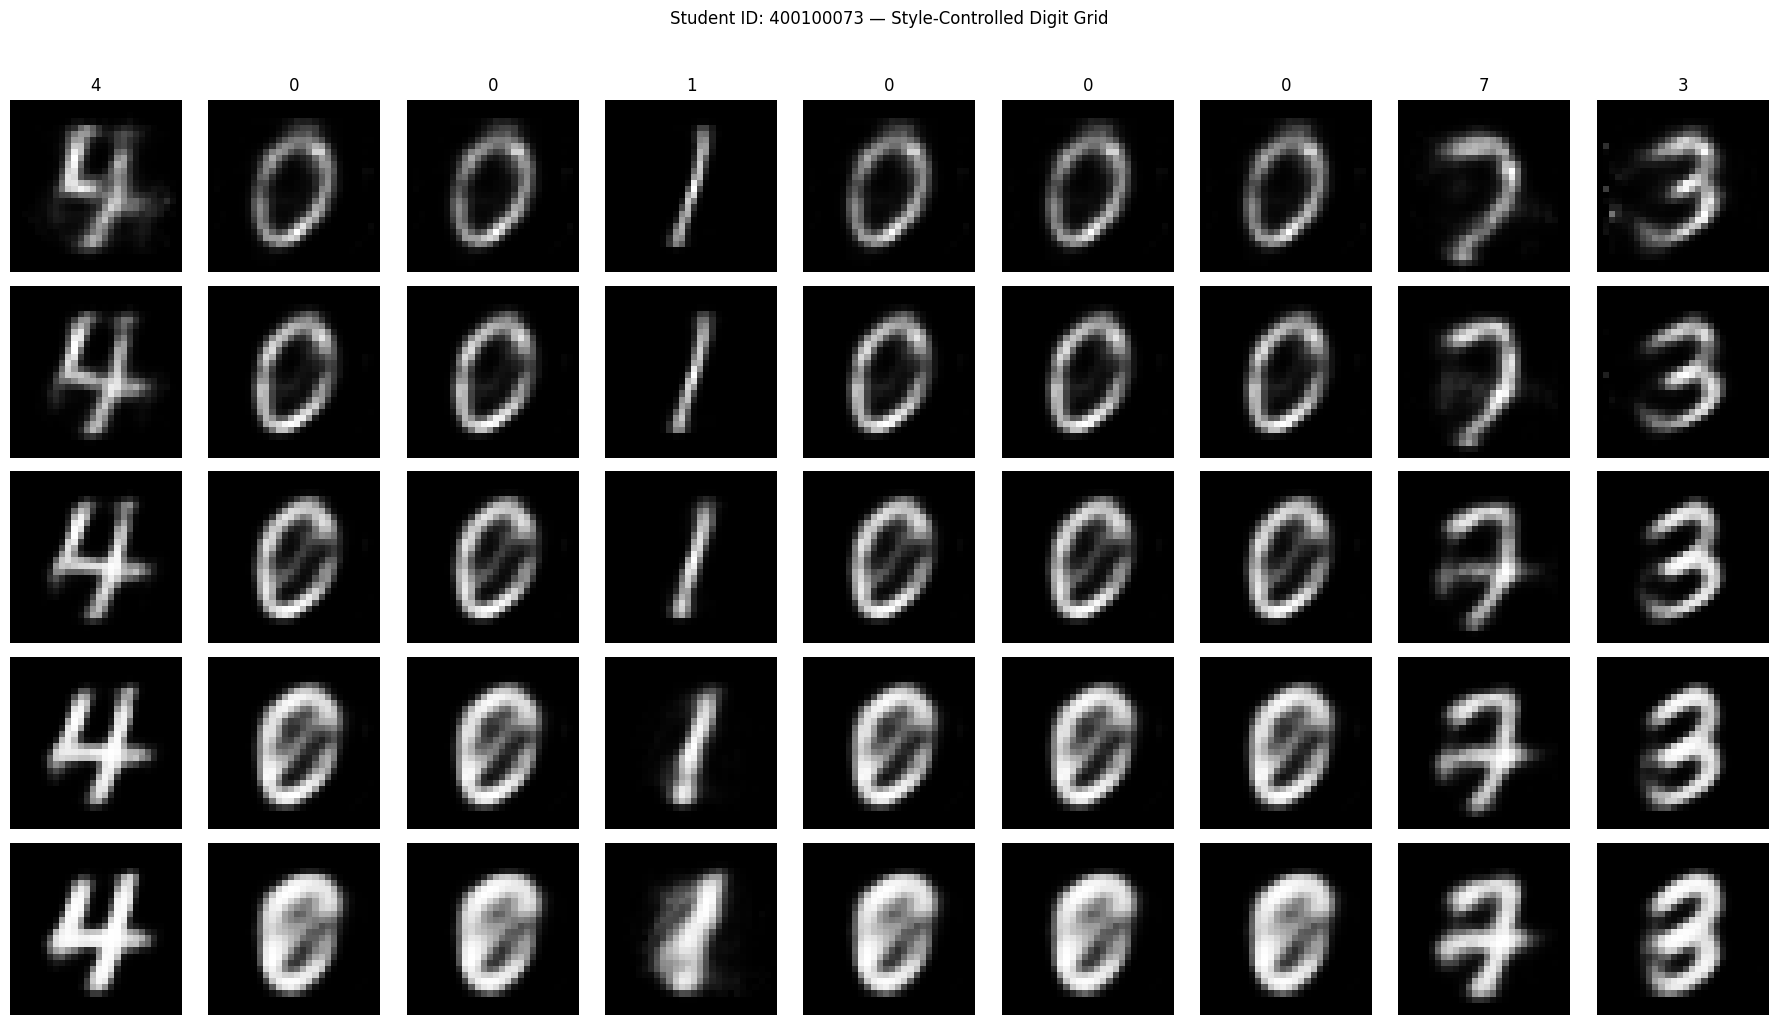

In [53]:
def generate_student_digits_style_grid(model, student_id, device='cpu', img_size=28):
    model.to(device)
    model.eval()

    # Convert ID → list of digits
    digits = [int(d) for d in str(student_id)]
    num_digits = len(digits)
    num_styles = 5  # number of style variations
    
    # One-hot-encoded labels
    y = torch.tensor(digits, dtype=torch.long, device=device)
    y_onehot = F.one_hot(y, num_classes=model.decoder.y_dim).float()

    # Latent dimensions
    z_total = model.decoder.z_dim
    z_dim = model.encoder.z_dim
    z_dim_controlled = z_total - z_dim   # last dims = style dims
    
    # Linearly sweep the first controlled dimension
    style_values = torch.linspace(-2, 2, num_styles, device=device)

    # Prepare plot
    plt.figure(figsize=(num_digits * 2, num_styles * 2))

    with torch.no_grad():
        for style_i, val in enumerate(style_values):

            # Build the full latent batch for this style row
            z = torch.zeros(num_digits, z_total, device=device)

            # Only the *first* controlled dimension varies
            z[:, 1] = val

            # Decode images
            x_gen = torch.sigmoid(model.decoder(z, y_onehot)).cpu()
            x_gen = x_gen.view(num_digits, img_size, img_size)

            # Plot each digit
            for j in range(num_digits):
                idx = style_i * num_digits + j + 1
                plt.subplot(num_styles, num_digits, idx)
                plt.imshow(x_gen[j], cmap='gray')
                if style_i == 0:
                    plt.title(digits[j])
                plt.axis('off')

    plt.suptitle(f"Student ID: {student_id} — Style-Controlled Digit Grid", y=1.02)
    plt.tight_layout()
    plt.show()

generate_student_digits_style_grid(model, 400100073)